In [1]:
import torch

print(torch.cuda.is_available())

True


In [2]:
!pip install -q ultralytics

In [5]:
import zipfile

zip_path = "/content/human-detection-ae.zip"

with zipfile.ZipFile(zip_path, 'r') as file:
    file.extractall("/content/dataset")

In [6]:
import os
import pandas as pd

print(os.listdir("/content/dataset"))

['test_images', 'sample_submission.csv']


In [7]:
images_path = "/content/dataset/test_images"

images = [
    f for f in os.listdir(images_path)
    if f.lower().endswith(".jpg")
]

print("Number of images:", len(images))

Number of images: 0


In [8]:
sample = pd.read_csv(
    "/content/dataset/sample_submission.csv"
)

print(sample.shape)
print(sample.head())

(590, 2)
     image_id                            PredictionString
0  test_00001  0 0.95 0.500000 0.500000 0.200000 0.400000
1  test_00002                                         NaN
2  test_00003                                         NaN
3  test_00004                                         NaN
4  test_00005                                         NaN


In [9]:
from ultralytics import YOLO

model = YOLO("yolo11m.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [10]:
print(model.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [11]:
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    classes=[0],
    conf=0.25,
    iou=0.45,
    imgsz=640,
    device=0
)


image 1/1 /content/bus.jpg: 640x480 4 persons, 29.2ms
Speed: 93.9ms preprocess, 29.2ms inference, 80.7ms postprocess per image at shape (1, 3, 640, 480)


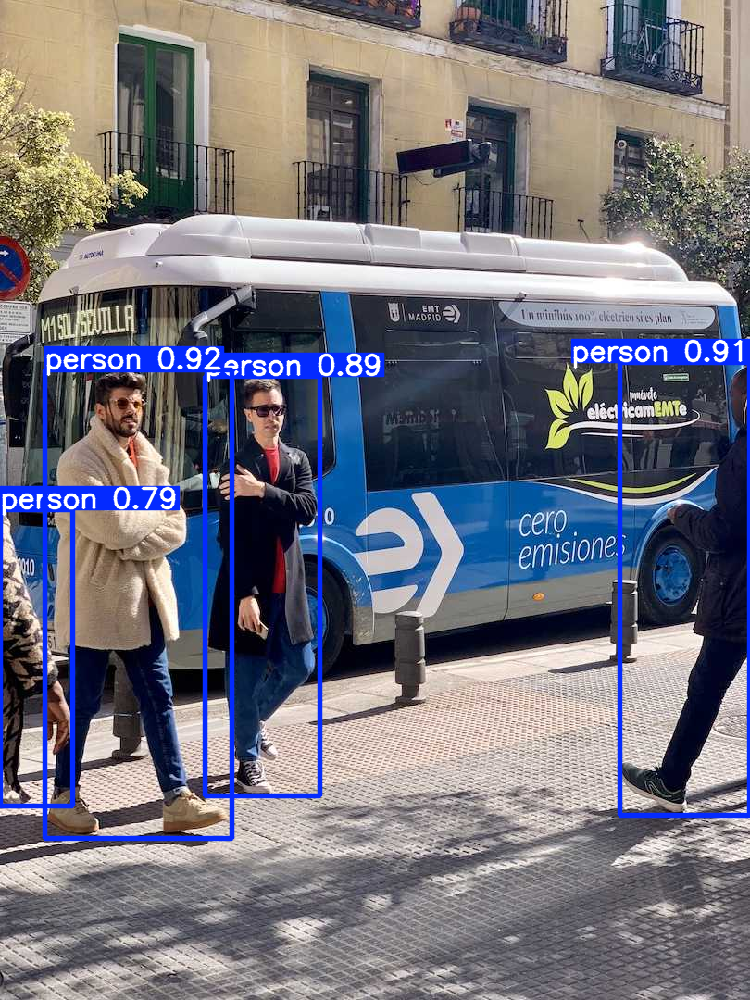

In [12]:
from google.colab.patches import cv2_imshow

cv2_imshow(results[0].plot())

In [13]:
print("Bounding Boxes:")
print(results[0].boxes.xywhn)

print("Confidence Scores:")
print(results[0].boxes.conf)

print("Class IDs:")
print(results[0].boxes.cls)

Bounding Boxes:
tensor([[0.1843, 0.6041, 0.2488, 0.4684],
        [0.9128, 0.5889, 0.1735, 0.4529],
        [0.3502, 0.5865, 0.1530, 0.4196],
        [0.0487, 0.6579, 0.0968, 0.2955]], device='cuda:0')
Confidence Scores:
tensor([0.9163, 0.9072, 0.8935, 0.7869], device='cuda:0')
Class IDs:
tensor([0., 0., 0., 0.], device='cuda:0')


In [15]:
import os

for root, dirs, files in os.walk("/content/dataset"):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:5])
    print()

Folder: /content/dataset
Number of files: 1
Sample files: ['sample_submission.csv']

Folder: /content/dataset/test_images
Number of files: 0
Sample files: []

Folder: /content/dataset/test_images/test_images
Number of files: 605
Sample files: ['test_00585.jpg', 'test_00045.jpg', 'test_00440.jpg', 'test_00076.jpg', 'test_00518.jpg']



In [16]:
from pathlib import Path

dataset_dir = Path("/content/dataset")

image_files = [
    p for p in dataset_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in
    [".jpg", ".jpeg", ".png"]
]

image_map = {
    p.stem: str(p)
    for p in image_files
}

image_paths = [
    image_map[image_id]
    for image_id in sample["image_id"]
    if image_id in image_map
]

missing = [
    image_id
    for image_id in sample["image_id"]
    if image_id not in image_map
]

print("Found images:", len(image_files))
print("Required images:", len(sample))
print("Matched images:", len(image_paths))
print("Missing images:", len(missing))

assert len(missing) == 0

Found images: 605
Required images: 590
Matched images: 590
Missing images: 0


In [18]:
import gc
import torch

results = None

gc.collect()
torch.cuda.empty_cache()

In [19]:
import time
from tqdm.auto import tqdm

start = time.time()

predictions = {}

batch_size = 4

for i in tqdm(range(0, len(image_paths), batch_size)):

    batch = image_paths[i:i + batch_size]

    results = model.predict(
        source=batch,
        classes=[0],
        conf=0.25,
        iou=0.45,
        imgsz=640,
        device=0,
        half=True,
        stream=True,
        verbose=False
    )

    for result in results:

        image_id = Path(result.path).stem

        boxes = result.boxes.xywhn.cpu().tolist()
        scores = result.boxes.conf.cpu().tolist()

        predictions[image_id] = list(zip(scores, boxes))

print("Processed images:", len(predictions))
print("Time:", round(time.time() - start, 2), "seconds")

  0%|          | 0/148 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [20]:
print("Processed images:", len(predictions))

Processed images: 590


In [21]:
import numpy as np

counts = [
    len(detections)
    for detections in predictions.values()
]

all_scores = [
    score
    for detections in predictions.values()
    for score, box in detections
]

print("Total images:", len(counts))
print("Total detections:", sum(counts))
print("Images without detections:", counts.count(0))
print("Average detections per image:", np.mean(counts))

if all_scores:
    print("Average confidence:", np.mean(all_scores))

Total images: 590
Total detections: 373
Images without detections: 282
Average detections per image: 0.6322033898305085
Average confidence: 0.5931249214560992


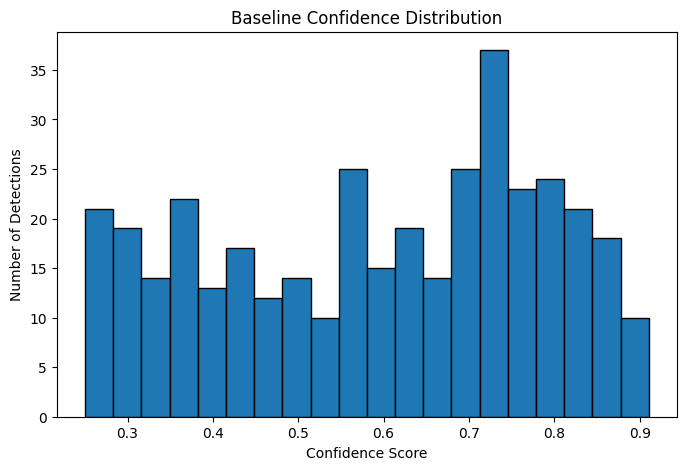

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(all_scores, bins=20, edgecolor="black")

plt.xlabel("Confidence Score")
plt.ylabel("Number of Detections")
plt.title("Baseline Confidence Distribution")

plt.show()

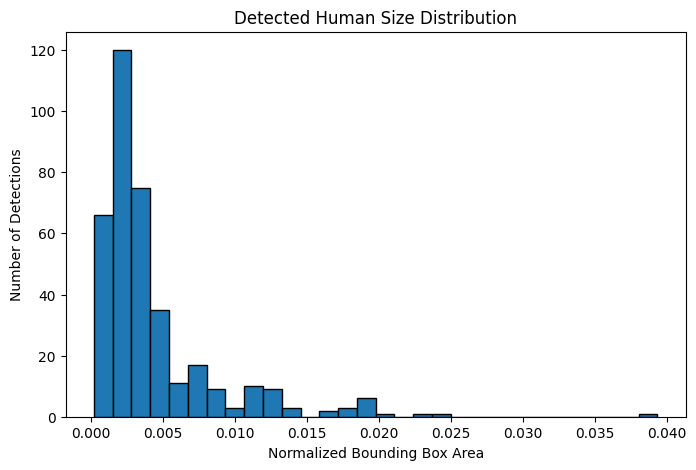

In [23]:
areas = [
    box[2] * box[3]
    for detections in predictions.values()
    for score, box in detections
]

plt.figure(figsize=(8, 5))

plt.hist(areas, bins=30, edgecolor="black")

plt.xlabel("Normalized Bounding Box Area")
plt.ylabel("Number of Detections")
plt.title("Detected Human Size Distribution")

plt.show()

In [24]:
def format_predictions(detections, class_id=1):

    parts = []

    for score, box in detections:

        x, y, w, h = box

        detection = (
            f"{class_id} {score:.6f} "
            f"{x:.6f} {y:.6f} "
            f"{w:.6f} {h:.6f}"
        )

        parts.append(detection)

    return " ".join(parts)

In [25]:
assert set(predictions) == set(sample["image_id"])

submission = sample[["image_id"]].copy()

submission["PredictionString"] = [
    format_predictions(predictions[image_id])
    for image_id in submission["image_id"]
]

print(submission.shape)
print(submission.head())

(590, 2)
     image_id                                PredictionString
0  test_00001  1 0.847656 0.412891 0.202009 0.075781 0.236607
1  test_00002  1 0.830566 0.404785 0.573611 0.074805 0.144444
2  test_00003                                                
3  test_00004                                                
4  test_00005                                                


In [26]:
submission.to_csv(
    "/content/submission_baseline.csv",
    index=False
)

In [27]:
from google.colab import files

files.download("/content/submission_baseline.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
check = pd.read_csv(
    "/content/submission_baseline.csv",
    keep_default_na=False
)

print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("Unique IDs:", check["image_id"].nunique())

print("Correct ID ordering:",
      check["image_id"].equals(sample["image_id"]))

print("Invalid prediction strings:",
      sum(len(s.split()) % 6 != 0
          for s in check["PredictionString"]))

print(check.head(10).to_string())

Shape: (590, 2)
Columns: ['image_id', 'PredictionString']
Unique IDs: 590
Correct ID ordering: True
Invalid prediction strings: 0
     image_id                                PredictionString
0  test_00001  1 0.847656 0.412891 0.202009 0.075781 0.236607
1  test_00002  1 0.830566 0.404785 0.573611 0.074805 0.144444
2  test_00003                                                
3  test_00004                                                
4  test_00005                                                
5  test_00006                                                
6  test_00007                                                
7  test_00008                                                
8  test_00009  1 0.455078 0.366797 0.686111 0.044922 0.094444
9  test_00010  1 0.735840 0.584766 0.626389 0.038281 0.058333


In [33]:
submission = submission.copy()

submission["PredictionString"] = (
    submission["PredictionString"]
    .fillna("")
    .replace("", " ")
)

submission.to_csv(
    "/content/submission_baseline.csv",
    index=False
)

In [34]:
check_fixed = pd.read_csv(
    "/content/submission_baseline.csv"
)

print("Null values:")
print(check_fixed.isnull().sum())

print("Shape:", check_fixed.shape)

Null values:
image_id            0
PredictionString    0
dtype: int64
Shape: (590, 2)


In [35]:
from google.colab import files

files.download("/content/submission_baseline.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
def format_predictions(detections, class_id=1):
    parts = []

    for score, box in detections:
        x, y, w, h = box

        parts.append(
            f"{class_id} {x:.6f} {y:.6f} "
            f"{w:.6f} {h:.6f}"
        )

    return " ".join(parts) if parts else " "


submission = sample[["image_id"]].copy()

submission["PredictionString"] = [
    format_predictions(predictions[image_id])
    for image_id in submission["image_id"]
]

submission.to_csv(
    "/content/corrected.csv",
    index=False
)

In [40]:
check = pd.read_csv("/content/corrected.csv")

print("Shape:", check.shape)
print("Null values:", check.isnull().sum().sum())
print("Invalid strings:",
      sum(len(s.split()) % 5 != 0
          for s in check["PredictionString"]))

print(check.head(10))

Shape: (590, 2)
Null values: 0
Invalid strings: 0
     image_id                       PredictionString
0  test_00001  1 0.412891 0.202009 0.075781 0.236607
1  test_00002  1 0.404785 0.573611 0.074805 0.144444
2  test_00003                                       
3  test_00004                                       
4  test_00005                                       
5  test_00006                                       
6  test_00007                                       
7  test_00008                                       
8  test_00009  1 0.366797 0.686111 0.044922 0.094444
9  test_00010  1 0.584766 0.626389 0.038281 0.058333


In [41]:
from google.colab import files

files.download("/content/corrected.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
import json

baseline_predictions = predictions.copy()

with open("/content/E1_predictions.json", "w") as f:
    json.dump(baseline_predictions, f)

In [43]:
import time
from tqdm.auto import tqdm
from pathlib import Path

def run_inference(model, image_paths,
                  imgsz=640,
                  conf=0.25,
                  iou=0.45,
                  batch_size=2):

    start = time.time()
    output = {}

    for i in tqdm(range(0, len(image_paths), batch_size)):

        batch = image_paths[i:i + batch_size]

        results = model.predict(
            source=batch,
            classes=[0],
            conf=conf,
            iou=iou,
            imgsz=imgsz,
            device=0,
            half=True,
            stream=True,
            verbose=False
        )

        for result in results:

            image_id = Path(result.path).stem

            boxes = result.boxes.xywhn.cpu().tolist()
            scores = result.boxes.conf.cpu().tolist()

            output[image_id] = list(zip(scores, boxes))

    elapsed = time.time() - start

    print("Processed images:", len(output))
    print("Runtime:", round(elapsed, 2), "seconds")

    return output

In [44]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

highres_predictions = run_inference(
    model,
    image_paths,
    imgsz=1280,
    conf=0.25,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/295 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [45]:
import numpy as np
import pandas as pd

def summarize(predictions):

    counts = [len(d) for d in predictions.values()]

    scores = [
        score
        for detections in predictions.values()
        for score, box in detections
    ]

    areas = [
        box[2] * box[3]
        for detections in predictions.values()
        for score, box in detections
    ]

    return {
        "Total images": len(counts),
        "Total detections": sum(counts),
        "Empty images": counts.count(0),
        "Mean confidence": np.mean(scores) if scores else 0,
        "Small detections": sum(a < 0.005 for a in areas)
    }


comparison = pd.DataFrame({
    "E1 - 640": summarize(baseline_predictions),
    "E2 - 1280": summarize(highres_predictions)
})

display(comparison)

,E1 - 640,E2 - 1280
Total images,590.000000,590.000000
Total detections,373.000000,421.000000
Empty images,282.000000,249.000000
Mean confidence,0.593125,0.656315
Small detections,290.000000,318.000000


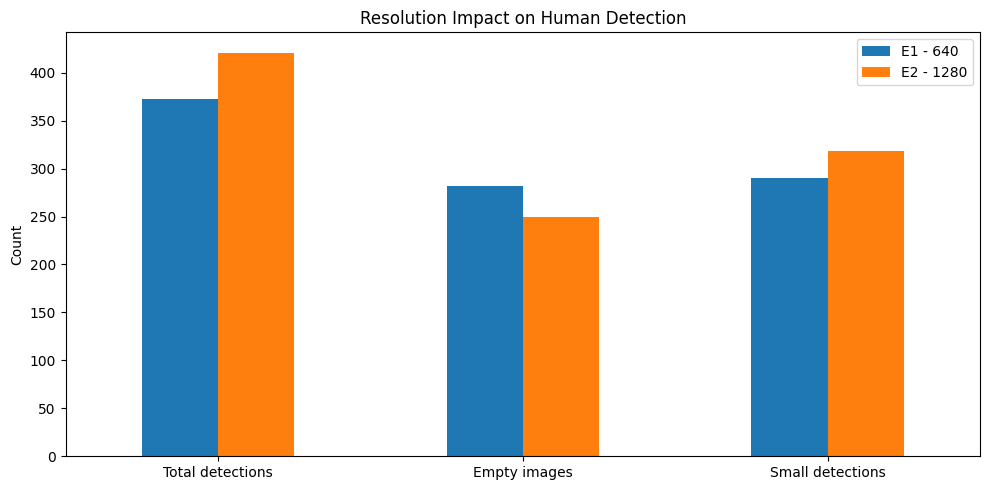

In [46]:
import matplotlib.pyplot as plt

metrics = [
    "Total detections",
    "Empty images",
    "Small detections"
]

comparison.loc[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Resolution Impact on Human Detection")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
with open("/content/E2_predictions.json", "w") as f:
    json.dump(highres_predictions, f)

In [48]:
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip -O /content/visdrone_val.zip

/content/visdrone_v 100%[===================>]  77.86M   138MB/s    in 0.6s    


In [49]:
with zipfile.ZipFile(
    "/content/visdrone_val.zip", "r"
) as file:

    file.extractall("/content/visdrone")

In [50]:
for root, dirs, files in os.walk("/content/visdrone"):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Examples:", files[:3])
    print()

Folder: /content/visdrone
Number of files: 0
Examples: []

Folder: /content/visdrone/VisDrone2019-DET-val
Number of files: 1
Examples: ['.DS_Store']

Folder: /content/visdrone/VisDrone2019-DET-val/annotations
Number of files: 548
Examples: ['0000276_01201_d_0000513.txt', '0000154_01601_d_0000001.txt', '0000069_00483_d_0000002.txt']

Folder: /content/visdrone/VisDrone2019-DET-val/images
Number of files: 548
Examples: ['0000356_02941_d_0000644.jpg', '0000276_00601_d_0000510.jpg', '0000215_02319_d_0000261.jpg']



In [51]:
from pathlib import Path

val_dir = Path("/content/visdrone/VisDrone2019-DET-val")

val_images_dir = val_dir / "images"
val_annotations_dir = val_dir / "annotations"

val_image_paths = sorted(
    str(p) for p in val_images_dir.glob("*.jpg")
)

print("Validation images:", len(val_image_paths))

assert all(
    (val_annotations_dir / (Path(p).stem + ".txt")).exists()
    for p in val_image_paths
)

Validation images: 548


In [52]:
annotation_path = (
    val_annotations_dir /
    (Path(val_image_paths[0]).stem + ".txt")
)

with open(annotation_path) as f:
    print(f.read()[:1500])

871,572,54,92,1,4,0,0
948,592,62,92,1,4,0,0
874,705,67,110,1,4,0,1
971,791,27,54,1,10,0,1
976,794,19,38,1,2,0,1
414,921,48,46,1,10,0,1
447,1054,27,26,1,1,1,0
430,902,27,49,1,1,0,1
405,837,55,52,1,8,0,1
416,856,19,36,1,2,0,1
349,796,60,61,1,8,0,1
378,753,39,44,1,10,0,1
630,722,56,43,1,10,0,1
651,745,93,42,1,7,0,1
488,775,50,58,1,10,0,1
543,781,69,40,1,7,0,1
569,756,49,34,1,10,0,1
571,720,48,31,1,10,0,1
602,684,46,29,1,10,0,1
519,743,45,29,1,10,0,1
518,724,50,27,1,10,0,1
603,652,48,49,1,8,0,1
537,700,56,35,1,10,0,1
536,667,63,58,1,8,0,1
531,625,46,52,1,8,0,1
555,583,45,42,1,8,0,1
567,581,49,38,1,10,0,1
613,599,42,29,1,10,0,1
663,588,43,30,1,10,0,1
637,611,41,27,1,10,0,1
629,630,45,30,1,10,0,1
447,547,52,42,1,8,0,0
464,523,38,30,1,10,0,1
565,555,48,37,1,8,0,1
591,544,52,33,1,10,0,1
609,511,42,43,1,8,0,1
595,515,55,26,1,10,0,2
580,451,17,37,1,1,0,1
535,445,36,28,1,10,0,1
489,440,40,43,1,8,0,0
488,450,41,27,1,10,0,1
491,445,38,24,1,10,0,1
504,431,36,26,1,10,0,2
655,535,45,26,1,3,0,1
660,524

In [53]:
import cv2

ground_truth = {}
ignored_regions = {}

for path in val_image_paths:

    image_id = Path(path).stem

    image = cv2.imread(path)
    H, W = image.shape[:2]

    annotation_file = (
        val_annotations_dir / f"{image_id}.txt"
    )

    human_boxes = []
    ignored_boxes = []

    with open(annotation_file) as f:

        for line in f:

            if not line.strip():
                continue

            values = line.strip().split(",")

            x, y, w, h = map(float, values[:4])
            score = int(values[4])
            category = int(values[5])

            if w <= 0 or h <= 0:
                continue

            box = [
                (x + w / 2) / W,
                (y + h / 2) / H,
                w / W,
                h / H
            ]

            if score == 0 or category == 0:
                ignored_boxes.append(box)

            elif category in [1, 2]:
                human_boxes.append(box)

    ground_truth[image_id] = human_boxes
    ignored_regions[image_id] = ignored_boxes

print("Validation images:", len(ground_truth))

print("Total ground-truth humans:",
      sum(len(b) for b in ground_truth.values()))

Validation images: 548
Total ground-truth humans: 13969


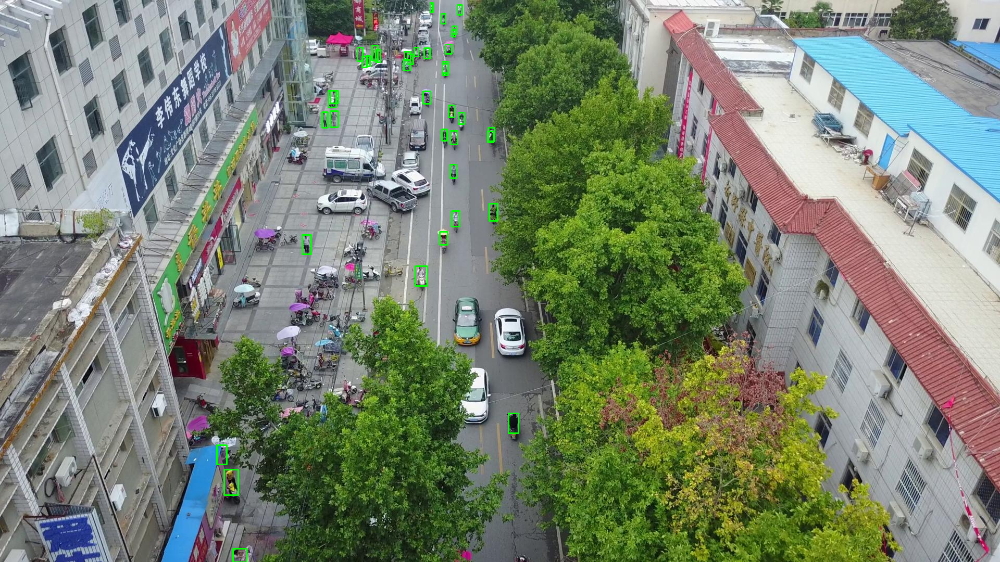

In [54]:
from google.colab.patches import cv2_imshow

path = val_image_paths[0]
image_id = Path(path).stem

image = cv2.imread(path)
H, W = image.shape[:2]

for x, y, w, h in ground_truth[image_id]:

    x1 = int((x - w/2) * W)
    y1 = int((y - h/2) * H)

    x2 = int((x + w/2) * W)
    y2 = int((y + h/2) * H)

    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

cv2_imshow(image)

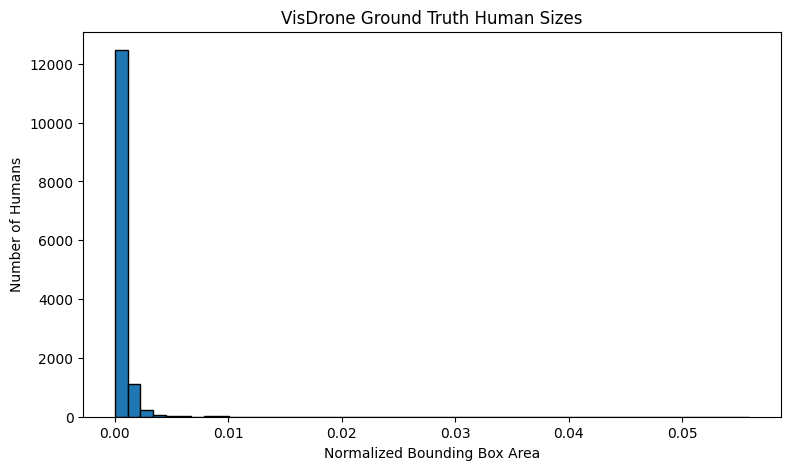

Percentage of small humans: 99.3915097716372


In [55]:
gt_areas = [
    box[2] * box[3]
    for boxes in ground_truth.values()
    for box in boxes
]

plt.figure(figsize=(9, 5))

plt.hist(gt_areas, bins=50, edgecolor="black")

plt.xlabel("Normalized Bounding Box Area")
plt.ylabel("Number of Humans")
plt.title("VisDrone Ground Truth Human Sizes")

plt.show()

print("Percentage of small humans:",
      100 * np.mean(np.array(gt_areas) < 0.005))

In [56]:
def xywh_to_xyxy(box):

    x, y, w, h = box

    return [
        x - w/2,
        y - h/2,
        x + w/2,
        y + h/2
    ]


def calculate_iou(box1, box2):

    a = xywh_to_xyxy(box1)
    b = xywh_to_xyxy(box2)

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])

    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area1 = box1[2] * box1[3]
    area2 = box2[2] * box2[3]

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [57]:
box1 = [0.5, 0.5, 0.2, 0.2]

print("Identical:",
      calculate_iou(box1, box1))

print("No overlap:",
      calculate_iou(box1, [0.9, 0.9, 0.1, 0.1]))

print("Partial overlap:",
      calculate_iou(box1, [0.6, 0.5, 0.2, 0.2]))

Identical: 0.9999999999999987
No overlap: 0.0
Partial overlap: 0.33333333333333304


In [58]:
def match_boxes(pred_boxes, gt_boxes):

    candidates = []

    for p, pred in enumerate(pred_boxes):

        for g, gt in enumerate(gt_boxes):

            iou = calculate_iou(pred, gt)

            if iou >= 0.15:
                candidates.append((iou, p, g))

    candidates.sort(reverse=True)

    used_predictions = set()
    used_ground_truth = set()

    matched_ious = []

    for iou, p, g in candidates:

        if p in used_predictions:
            continue

        if g in used_ground_truth:
            continue

        used_predictions.add(p)
        used_ground_truth.add(g)

        matched_ious.append(iou)

    return matched_ious

In [59]:
def evaluate_predictions(predictions, ground_truth,
                         conf_threshold=0.25):

    hard_tp = 0
    soft_tp = 0

    total_predictions = 0
    total_ground_truth = 0

    for image_id, gt_boxes in ground_truth.items():

        detections = predictions.get(image_id, [])

        pred_boxes = [
            box for score, box in detections
            if score >= conf_threshold
        ]

        matched_ious = match_boxes(
            pred_boxes, gt_boxes
        )

        total_predictions += len(pred_boxes)
        total_ground_truth += len(gt_boxes)

        hard_tp += sum(
            iou >= 0.30 for iou in matched_ious
        )

        soft_tp += sum(
            min(1.0, iou / 0.30)
            for iou in matched_ious
        )

    denominator = (
        total_predictions + total_ground_truth
    )

    hard_f1 = (
        2 * hard_tp / denominator
        if denominator else 0
    )

    soft_f1 = (
        2 * soft_tp / denominator
        if denominator else 0
    )

    final_score = (hard_f1 + soft_f1) / 2

    return {
        "Hard F1": hard_f1,
        "Soft F1": soft_f1,
        "Final Score": final_score,
        "Predictions": total_predictions,
        "Ground Truth": total_ground_truth
    }

In [60]:
val_predictions_640 = run_inference(
    model,
    val_image_paths,
    imgsz=640,
    conf=0.05,
    iou=0.45,
    batch_size=4
)

  0%|          | 0/137 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [61]:
val_predictions_1280 = run_inference(
    model,
    val_image_paths,
    imgsz=1280,
    conf=0.05,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/274 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [62]:
validation_comparison = pd.DataFrame({

    "E1 - 640": evaluate_predictions(
        val_predictions_640,
        ground_truth,
        conf_threshold=0.25
    ),

    "E2 - 1280": evaluate_predictions(
        val_predictions_1280,
        ground_truth,
        conf_threshold=0.25
    )
})

display(validation_comparison)

,E1 - 640,E2 - 1280
Hard F1,0.265675,0.498456
Soft F1,0.266906,0.500045
Final Score,0.266290,0.499251
Predictions,2299.000000,5142.000000
Ground Truth,13969.000000,13969.000000


In [63]:
thresholds = [
    0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.35, 0.40,
    0.45, 0.50
]

threshold_results = []

for conf in tqdm(thresholds):

    metrics = evaluate_predictions(
        val_predictions_1280,
        ground_truth,
        conf_threshold=conf
    )

    threshold_results.append({
        "Confidence": conf,
        **metrics
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

  0%|          | 0/10 [00:00<?, ?it/s]

,Confidence,Hard F1,Soft F1,Final Score,Predictions,Ground Truth
0,0.05,0.627178,0.634680,0.630929,10764,13969
1,0.10,0.604535,0.609314,0.606925,8124,13969
2,0.15,0.569140,0.573212,0.571176,6757,13969
3,0.20,0.533898,0.536861,0.535380,5855,13969
4,0.25,0.498456,0.500045,0.499251,5142,13969
5,0.30,0.461023,0.462252,0.461637,4529,13969
6,0.35,0.425785,0.426715,0.426250,4026,13969
7,0.40,0.386093,0.386977,0.386535,3519,13969
8,0.45,0.345107,0.345388,0.345248,3046,13969
9,0.50,0.304007,0.304295,0.304151,2603,13969


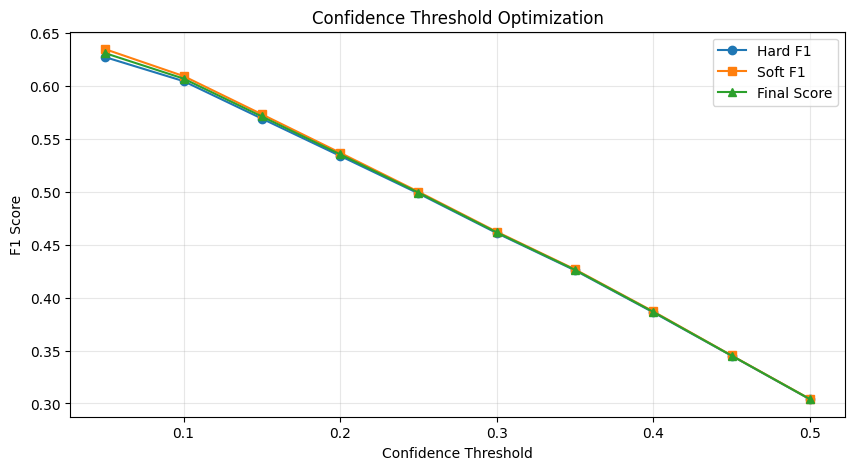

In [64]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Hard F1"],
    marker="o",
    label="Hard F1"
)

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Soft F1"],
    marker="s",
    label="Soft F1"
)

plt.plot(
    threshold_df["Confidence"],
    threshold_df["Final Score"],
    marker="^",
    label="Final Score"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("F1 Score")
plt.title("Confidence Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [65]:
best_row = threshold_df.loc[
    threshold_df["Final Score"].idxmax()
]

best_conf = float(best_row["Confidence"])

print("Best confidence:", best_conf)
print("Best validation score:", best_row["Final Score"])

print(
    "Improvement over E2:",
    best_row["Final Score"] - 0.499251
)

Best confidence: 0.05
Best validation score: 0.6309289496384411
Improvement over E2: 0.13167794963844115


In [66]:
val_predictions_lowconf = run_inference(
    model,
    val_image_paths,
    imgsz=1280,
    conf=0.01,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/274 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [67]:
low_thresholds = [
    0.01, 0.02, 0.03,
    0.04, 0.05, 0.075, 0.10
]

low_results = []

for conf in tqdm(low_thresholds):

    metrics = evaluate_predictions(
        val_predictions_lowconf,
        ground_truth,
        conf_threshold=conf
    )

    low_results.append({
        "Confidence": conf,
        **metrics
    })

low_df = pd.DataFrame(low_results)

display(low_df)

  0%|          | 0/7 [00:00<?, ?it/s]

,Confidence,Hard F1,Soft F1,Final Score,Predictions,Ground Truth
0,0.010,0.566870,0.577775,0.572322,19873,13969
1,0.020,0.610811,0.620447,0.615629,15261,13969
2,0.030,0.625009,0.634232,0.629621,13077,13969
3,0.040,0.629158,0.637394,0.633276,11732,13969
4,0.050,0.627178,0.634680,0.630929,10764,13969
5,0.075,0.618813,0.624796,0.621804,9185,13969
6,0.100,0.604535,0.609314,0.606925,8124,13969


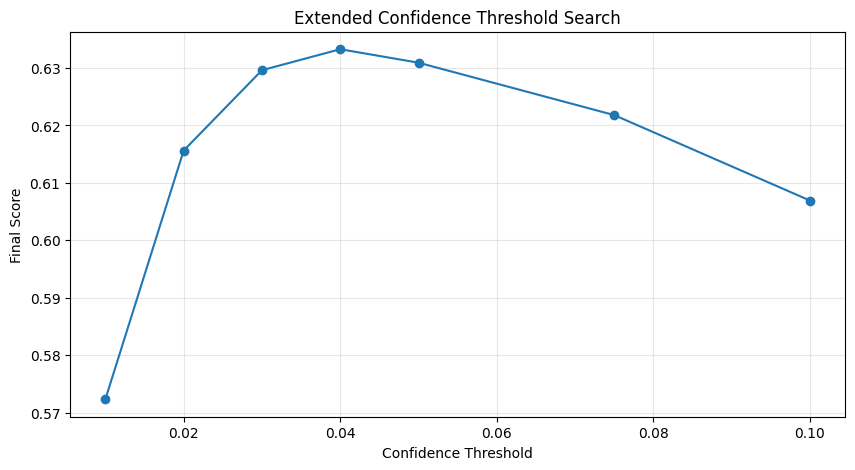

In [68]:
plt.figure(figsize=(10, 5))

plt.plot(
    low_df["Confidence"],
    low_df["Final Score"],
    marker="o"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Final Score")
plt.title("Extended Confidence Threshold Search")
plt.grid(alpha=0.3)

plt.show()

In [69]:
best_row = low_df.loc[
    low_df["Final Score"].idxmax()
]

best_conf = float(best_row["Confidence"])

print("Best Confidence:", best_conf)
print("Best Score:", best_row["Final Score"])

Best Confidence: 0.04
Best Score: 0.6332761877497725


### Confidence Threshold Analysis

The initial confidence threshold of 0.25 was found to be overly restrictive for aerial human detection on the VisDrone validation set.

Reducing the threshold to 0.05 increased the local blended F1 score from 0.49925 to 0.63093 at an input resolution of 1280 pixels.

Since the best observed score occurred at the lower boundary of the tested range, an extended threshold search was conducted to investigate whether further improvements were possible.

In [70]:
optimized_predictions = run_inference(
    model,
    image_paths,
    imgsz=1280,
    conf=best_conf,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/295 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [72]:
submission_e3 = sample[["image_id"]].copy()

submission_e3["PredictionString"] = [
    format_predictions(optimized_predictions[image_id])
    for image_id in submission_e3["image_id"]
]

submission_e3.to_csv(
    "/content/E3_optimized.csv",
    index=False
)

from google.colab import files as colab_files

colab_files.download("/content/E3_optimized.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip -O /content/visdrone_train.zip

/content/visdrone_t 100%[===================>]   1.44G  30.4MB/s    in 24s     


In [74]:
import zipfile

with zipfile.ZipFile(
    "/content/visdrone_train.zip", "r"
) as file:

    file.extractall("/content/visdrone")

In [75]:
train_dir = Path(
    "/content/visdrone/VisDrone2019-DET-train"
)

train_images = sorted(
    (train_dir / "images").glob("*.jpg")
)

train_annotations = sorted(
    (train_dir / "annotations").glob("*.txt")
)

print("Training images:", len(train_images))
print("Training annotations:", len(train_annotations))

Training images: 6471
Training annotations: 6471


In [76]:
import cv2
from tqdm.auto import tqdm

def convert_visdrone_to_yolo(dataset_dir):

    images_dir = dataset_dir / "images"
    annotations_dir = dataset_dir / "annotations"
    labels_dir = dataset_dir / "labels"

    labels_dir.mkdir(exist_ok=True)

    total_humans = 0
    empty_images = 0

    for image_path in tqdm(sorted(images_dir.glob("*.jpg"))):

        image = cv2.imread(str(image_path))
        H, W = image.shape[:2]

        annotation_path = (
            annotations_dir / f"{image_path.stem}.txt"
        )

        yolo_labels = []

        with open(annotation_path) as f:

            for line in f:

                if not line.strip():
                    continue

                values = line.strip().split(",")

                x, y, w, h = map(float, values[:4])
                score = int(values[4])
                category = int(values[5])

                if score == 0 or category not in [1, 2]:
                    continue

                x1 = max(0, x)
                y1 = max(0, y)
                x2 = min(W, x + w)
                y2 = min(H, y + h)

                if x2 <= x1 or y2 <= y1:
                    continue

                xc = (x1 + x2) / (2 * W)
                yc = (y1 + y2) / (2 * H)

                bw = (x2 - x1) / W
                bh = (y2 - y1) / H

                yolo_labels.append(
                    f"0 {xc:.6f} {yc:.6f} "
                    f"{bw:.6f} {bh:.6f}"
                )

                total_humans += 1

        if not yolo_labels:
            empty_images += 1

        label_path = labels_dir / f"{image_path.stem}.txt"

        label_path.write_text("\n".join(yolo_labels))

    print("Total humans:", total_humans)
    print("Images without labeled humans:", empty_images)

In [77]:
print("Converting training dataset...")

convert_visdrone_to_yolo(train_dir)

print("\nConverting validation dataset...")

convert_visdrone_to_yolo(val_dir)

Converting training dataset...


  0%|          | 0/6471 [00:00<?, ?it/s]

Total humans: 106396
Images without labeled humans: 787

Converting validation dataset...


  0%|          | 0/548 [00:00<?, ?it/s]

Total humans: 13969
Images without labeled humans: 17


In [78]:
import yaml

data_config = {
    "path": "/content/visdrone",

    "train": "VisDrone2019-DET-train/images",

    "val": "VisDrone2019-DET-val/images",

    "nc": 1,

    "names": {
        0: "human"
    }
}

yaml_path = "/content/visdrone/human_data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f)

print(Path(yaml_path).read_text())

names:
  0: human
nc: 1
path: /content/visdrone
train: VisDrone2019-DET-train/images
val: VisDrone2019-DET-val/images



In [79]:
!nvidia-smi

Wed Nov 25 01:23:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             32W /   70W |     869MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [80]:
import random

random.seed(42)

selected_images = random.sample(
    train_images, 2000
)

train_list_path = "/content/visdrone/train_subset.txt"

with open(train_list_path, "w") as f:
    f.write("\n".join(
        str(p) for p in selected_images
    ))

print("Selected training images:", len(selected_images))

Selected training images: 2000


In [81]:
subset_config = data_config.copy()

subset_config["train"] = train_list_path

subset_yaml = "/content/visdrone/human_subset.yaml"

with open(subset_yaml, "w") as f:
    yaml.safe_dump(subset_config, f)

print(Path(subset_yaml).read_text())

names:
  0: human
nc: 1
path: /content/visdrone
train: /content/visdrone/train_subset.txt
val: VisDrone2019-DET-val/images



In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

aerial_model = YOLO("yolo11m.pt")

training_results = aerial_model.train(

    data=subset_yaml,

    epochs=10,
    time=1.0,

    imgsz=960,
    batch=4,
    device=0,
    amp=True,

    degrees=180,
    fliplr=0.5,
    flipud=0.5,

    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.4,

    scale=0.5,
    translate=0.1,

    mosaic=0.5,
    mixup=0.0,
    close_mosaic=2,

    optimizer="AdamW",
    lr0=0.001,

    workers=2,
    cache=False,

    seed=42,
    patience=5,

    save=True,
    save_period=1,
    plots=True,

    project="/content/experiments",
    name="E4_aerial_finetuning"
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visdrone/human_subset.yaml, degrees=180, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=E4_aerial_finetuning, nbs=64, nms=None, opset=None, o

In [1]:
from pathlib import Path

print("Dataset exists:",
      Path("/content/visdrone").exists())

print("Saved checkpoints:")

for p in Path("/content/experiments").rglob("*.pt"):
    print(p)

Dataset exists: True
Saved checkpoints:


In [2]:
import torch
import gc
from pathlib import Path
from ultralytics import YOLO

gc.collect()
torch.cuda.empty_cache()

subset_yaml = "/content/visdrone/human_subset.yaml"

print("GPU available:", torch.cuda.is_available())
print("YAML exists:", Path(subset_yaml).exists())
print("Pretrained weights exist:", Path("/content/yolo11m.pt").exists())

GPU available: True
YAML exists: True
Pretrained weights exist: True


In [ ]:
aerial_model = YOLO("yolo11m.pt")

training_results = aerial_model.train(

    data=subset_yaml,

    epochs=10,

    imgsz=960,
    batch=2,
    device=0,
    amp=True,

    degrees=180,
    fliplr=0.5,
    flipud=0.5,

    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.4,

    scale=0.5,
    translate=0.1,

    mosaic=0.5,
    mixup=0.0,
    close_mosaic=2,

    optimizer="AdamW",
    lr0=0.001,

    workers=0,
    cache=False,

    seed=42,
    patience=5,

    save=True,
    save_period=1,
    plots=False,

    project="/content/experiments",
    name="E4_aerial_lowram"
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visdrone/human_subset.yaml, degrees=180, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=E4_aerial_lowram, nbs=64, nms=None, opset=None, optim

In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU available: True
Tesla T4


In [2]:
!pip install -q ultralytics

In [6]:
from pathlib import Path

print("Working directory:", Path.cwd())

print("Available datasets:")

for p in Path("/kaggle/input").iterdir():
    print(p)

Working directory: /kaggle/working
Available datasets:


In [ ]:
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip -O /kaggle/working/visdrone_train.zip

In [7]:
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip -O /kaggle/working/visdrone_val.zip

/kaggle/working/vis 100%[===================>]  77.86M   244MB/s    in 0.3s    


In [11]:
import zipfile

base_dir = Path("/kaggle/working/visdrone")

base_dir.mkdir(exist_ok=True)

for name in ["train", "val"]:

    zip_path = f"/kaggle/working/visdrone_{name}.zip"

    with zipfile.ZipFile(zip_path, "r") as file:
        file.extractall(base_dir)

In [9]:
!ls -lh /kaggle/working/

total 78M
drwxr-xr-x 2 root root 4.0K Nov 25 11:30 visdrone
-rw-r--r-- 1 root root  78M Jul 10  2024 visdrone_val.zip


In [10]:
from pathlib import Path
import zipfile
import subprocess

for name in ["train", "val"]:

    path = Path(
        f"/kaggle/working/visdrone_{name}.zip"
    )

    if not zipfile.is_zipfile(path):

        url = (
            "https://github.com/ultralytics/assets/"
            "releases/download/v0.0.0/"
            f"VisDrone2019-DET-{name}.zip"
        )

        subprocess.run(
            ["wget", "--show-progress", url,
             "-O", str(path)],
            check=True
        )

    print(name, "Valid ZIP:", zipfile.is_zipfile(path))

--2026-11-25 11:31:31--  https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/521807533/9137a849-834e-4c54-b2d5-14d12384f10f?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-11-25T12%3A20%3A14Z&rscd=attachment%3B+filename%3DVisDrone2019-DET-train.zip&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-11-25T11%3A19%3A42Z&ske=2026-11-25T12%3A20%3A14Z&sks=b&skv=2018-11-09&sig=0f2PNonMBlPdlNwhhyVqqmM%2FoSnE0tbrpCoQfZ%2F9r30%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5NTYwOTg5MSwibmJmIjoxNzk1NjA2MjkxLCJwYXRoIjoicmVsZWFzZ

train Valid ZIP: True
val Valid ZIP: True


.......... .......... 99%  160M 0s
1501000K .......... .......... .......... .......... .......... 99%  209M 0s
1501050K .......... .......... .......... .......... .......... 99%  315M 0s
1501100K .......... .......... .......... .......... .......... 99%  364M 0s
1501150K .......... .......... .......... .......... .......... 99%  295M 0s
1501200K .......... .......... .......... .......... .......... 99%  259M 0s
1501250K .......... .......... .......... .......... .......... 99%  219M 0s
1501300K .......... .......... .......... .......... .......... 99%  259M 0s
1501350K .......... .......... .......... .......... .......... 99%  260M 0s
1501400K .......... .......... .......... .......... .......... 99%  232M 0s
1501450K .......... .......... .......... .......... .......... 99%  220M 0s
1501500K .......... .......... .......... .......... .......... 99%  221M 0s
1501550K .......... .......... .......... .......... .......... 99%  165M 0s
1501600K .......... .......... ..........

In [12]:
train_dir = base_dir / "VisDrone2019-DET-train"
val_dir = base_dir / "VisDrone2019-DET-val"

train_images = sorted(
    (train_dir / "images").glob("*.jpg")
)

val_images = sorted(
    (val_dir / "images").glob("*.jpg")
)

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

Training images: 6471
Validation images: 548


In [13]:
!nvidia-smi
!free -h
!df -h /kaggle/working

Wed Nov 25 11:50:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [14]:
for p in Path("/kaggle/input").rglob("sample_submission.csv"):
    print(p)

/kaggle/input/competitions/human-detection-ae/sample_submission.csv


In [15]:
from pathlib import Path
import cv2
from tqdm.auto import tqdm

def convert_visdrone_to_yolo(dataset_dir):

    images_dir = dataset_dir / "images"
    annotations_dir = dataset_dir / "annotations"
    labels_dir = dataset_dir / "labels"

    labels_dir.mkdir(exist_ok=True)

    total_humans = 0

    for image_path in tqdm(sorted(images_dir.glob("*.jpg"))):

        image = cv2.imread(str(image_path))
        H, W = image.shape[:2]

        annotation_path = (
            annotations_dir / f"{image_path.stem}.txt"
        )

        yolo_labels = []

        with open(annotation_path) as f:

            for line in f:

                if not line.strip():
                    continue

                values = line.strip().split(",")

                x, y, w, h = map(float, values[:4])
                score = int(values[4])
                category = int(values[5])

                if score == 0 or category not in [1, 2]:
                    continue

                x1 = max(0, x)
                y1 = max(0, y)
                x2 = min(W, x + w)
                y2 = min(H, y + h)

                if x2 <= x1 or y2 <= y1:
                    continue

                xc = (x1 + x2) / (2 * W)
                yc = (y1 + y2) / (2 * H)

                bw = (x2 - x1) / W
                bh = (y2 - y1) / H

                yolo_labels.append(
                    f"0 {xc:.6f} {yc:.6f} "
                    f"{bw:.6f} {bh:.6f}"
                )

                total_humans += 1

        label_path = labels_dir / f"{image_path.stem}.txt"

        label_path.write_text("\n".join(yolo_labels))

    print("Total humans:", total_humans)

In [16]:
assert len(train_images) == 6471
assert len(val_images) == 548

print("Training labels:")
convert_visdrone_to_yolo(train_dir)

print("Validation labels:")
convert_visdrone_to_yolo(val_dir)

Training labels:


  0%|          | 0/6471 [00:00<?, ?it/s]

Total humans: 106396
Validation labels:


  0%|          | 0/548 [00:00<?, ?it/s]

Total humans: 13969


In [17]:
import yaml

data_config = {
    "path": "/kaggle/working/visdrone",
    "train": "VisDrone2019-DET-train/images",
    "val": "VisDrone2019-DET-val/images",
    "nc": 1,
    "names": {0: "human"}
}

yaml_path = "/kaggle/working/human_data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f)

print(Path(yaml_path).read_text())

names:
  0: human
nc: 1
path: /kaggle/working/visdrone
train: VisDrone2019-DET-train/images
val: VisDrone2019-DET-val/images



In [18]:
from ultralytics import YOLO

aerial_model = YOLO("yolo11m.pt")

training_results = aerial_model.train(

    data=yaml_path,

    epochs=8,
    time=1.0,

    imgsz=960,
    batch=8,
    device=0,
    amp=True,

    degrees=180,
    fliplr=0.5,
    flipud=0.5,

    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.4,

    scale=0.3,
    translate=0.1,

    mosaic=0.3,
    mixup=0.0,
    close_mosaic=2,

    optimizer="AdamW",
    lr0=0.0005,

    workers=0,
    cache=False,

    seed=42,
    patience=5,

    save=True,
    save_period=1,
    plots=False,

    project="/kaggle/working/experiments",
    name="E4_aerial_training"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/human_data.yaml, degrees=180, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, f

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


        2/6      11.5G      2.402      1.832      1.159         61        960: 100% ━━━━━━━━━━━━ 809/809 1.3it/s 10:060.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 2.3it/s 15.3s0.5s
                   all        548      13969       0.43      0.308       0.29     0.0824

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/6      9.88G      2.327      1.697      1.127        291        960: 100% ━━━━━━━━━━━━ 809/809 1.3it/s 10:060.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 2.3it/s 15.3s0.4s
                   all        548      13969      0.375      0.306      0.225     0.0477

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        4/6      11.7G       2.25      1.604      1.098        113        960: 100% ━━━━━━━━━━━━ 809/809 1.3it/s 10:050.7s
                 Class     Imag

In [19]:
from pathlib import Path
import shutil
from IPython.display import FileLink, display

training_dir = Path(
    "/kaggle/working/experiments/E4_aerial_training"
)

best_weights = training_dir / "weights/best.pt"

assert best_weights.is_file()

shutil.copy2(
    best_weights,
    "/kaggle/working/E4_aerial_best.pt"
)

display(FileLink("E4_aerial_best.pt"))

/kaggle/working/E4_aerial_best.pt

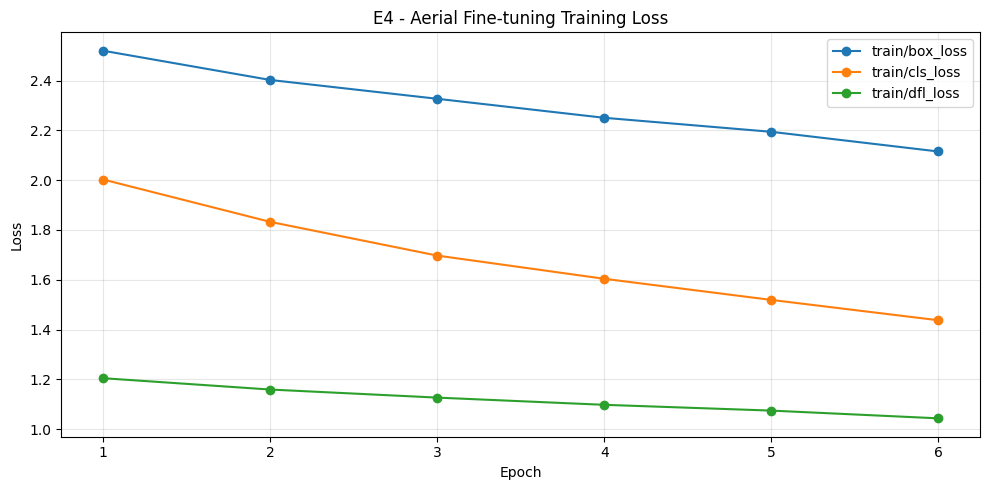

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv(training_dir / "results.csv")

history.columns = history.columns.str.strip()

plt.figure(figsize=(10, 5))

for column in [
    "train/box_loss",
    "train/cls_loss",
    "train/dfl_loss"
]:

    plt.plot(
        history["epoch"],
        history[column],
        marker="o",
        label=column
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("E4 - Aerial Fine-tuning Training Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/E4_training_loss.png",
    dpi=200
)

plt.show()

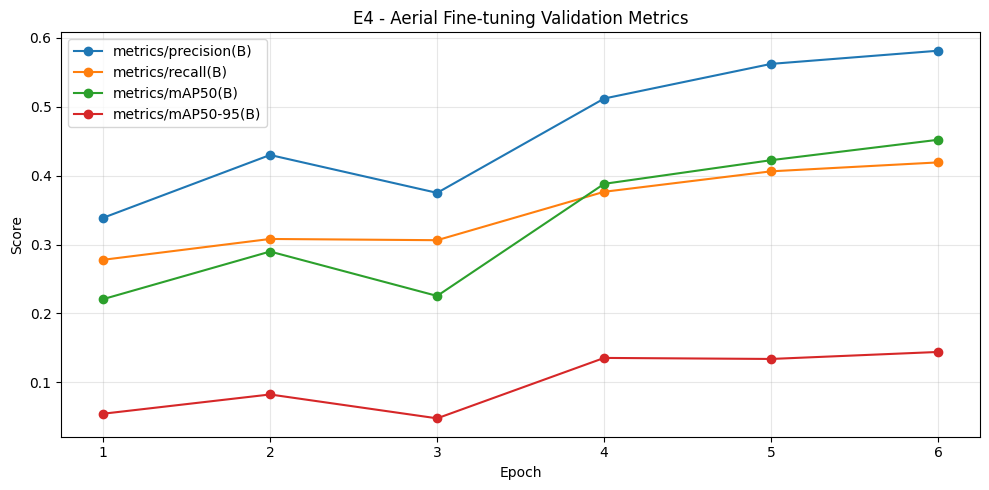

In [21]:
plt.figure(figsize=(10, 5))

for column in [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]:

    plt.plot(
        history["epoch"],
        history[column],
        marker="o",
        label=column
    )

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("E4 - Aerial Fine-tuning Validation Metrics")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/E4_validation_metrics.png",
    dpi=200
)

plt.show()

In [22]:
from ultralytics import YOLO

finetuned_model = YOLO(str(best_weights))

print(finetuned_model.names)

{0: 'human'}


In [23]:
val_image_paths = [
    str(p) for p in val_images
]

ground_truth = {}

for path in val_images:

    label_path = (
        val_dir / "labels" / f"{path.stem}.txt"
    )

    boxes = []

    for line in label_path.read_text().splitlines():

        values = line.split()

        boxes.append(
            list(map(float, values[1:5]))
        )

    ground_truth[path.stem] = boxes

print("Validation images:", len(ground_truth))

print(
    "Total humans:",
    sum(len(b) for b in ground_truth.values())
)

Validation images: 548
Total humans: 13969


In [25]:
import time
import torch
from tqdm.auto import tqdm
from pathlib import Path

def run_inference(model, paths, imgsz=1280,
                  conf=0.01, iou=0.45, batch_size=2):

    predictions = {}

    start = time.time()

    for i in tqdm(range(0, len(paths), batch_size)):

        batch = paths[i:i + batch_size]

        results = model.predict(
            source=batch,
            imgsz=imgsz,
            conf=conf,
            iou=iou,
            classes=[0],
            device=0,
            max_det=300,
            stream=True,
            verbose=False
        )

        for result in results:

            image_id = Path(result.path).stem

            boxes = result.boxes.xywhn.cpu().tolist()

            scores = result.boxes.conf.cpu().tolist()

            predictions[image_id] = list(
                zip(scores, boxes)
            )

    print("Processed images:", len(predictions))

    print("Time:", round(time.time() - start, 2),
          "seconds")

    return predictions

In [26]:
def xywh_to_xyxy(box):

    x, y, w, h = box

    return [
        x - w/2,
        y - h/2,
        x + w/2,
        y + h/2
    ]


def calculate_iou(box1, box2):

    a = xywh_to_xyxy(box1)
    b = xywh_to_xyxy(box2)

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])

    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area1 = box1[2] * box1[3]
    area2 = box2[2] * box2[3]

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [27]:
def match_boxes(pred_boxes, gt_boxes):

    candidates = []

    for p, pred in enumerate(pred_boxes):

        for g, gt in enumerate(gt_boxes):

            iou = calculate_iou(pred, gt)

            if iou >= 0.15:
                candidates.append((iou, p, g))

    candidates.sort(reverse=True)

    used_predictions = set()
    used_ground_truth = set()

    matched_ious = []

    for iou, p, g in candidates:

        if p in used_predictions:
            continue

        if g in used_ground_truth:
            continue

        used_predictions.add(p)
        used_ground_truth.add(g)

        matched_ious.append(iou)

    return matched_ious

In [29]:
def evaluate_predictions(predictions, ground_truth,
                         conf_threshold=0.25):

    hard_tp = 0
    soft_tp = 0

    total_predictions = 0
    total_ground_truth = 0

    for image_id, gt_boxes in ground_truth.items():

        detections = predictions.get(image_id, [])

        pred_boxes = [
            box for score, box in detections
            if score >= conf_threshold
        ]

        matched_ious = match_boxes(
            pred_boxes, gt_boxes
        )

        total_predictions += len(pred_boxes)
        total_ground_truth += len(gt_boxes)

        hard_tp += sum(
            iou >= 0.30 for iou in matched_ious
        )

        soft_tp += sum(
            min(1.0, iou / 0.30)
            for iou in matched_ious
        )

    denominator = (
        total_predictions + total_ground_truth
    )

    hard_f1 = (
        2 * hard_tp / denominator
        if denominator else 0
    )

    soft_f1 = (
        2 * soft_tp / denominator
        if denominator else 0
    )

    precision = (
        hard_tp / total_predictions
        if total_predictions else 0
    )

    recall = (
        hard_tp / total_ground_truth
        if total_ground_truth else 0
    )

    return {
        "Hard F1": hard_f1,
        "Soft F1": soft_f1,
        "Final Score": (hard_f1 + soft_f1) / 2,
        "Precision": precision,
        "Recall": recall,
        "Predictions": total_predictions,
        "Ground Truth": total_ground_truth
    }

In [30]:
import gc

gc.collect()
torch.cuda.empty_cache()

finetuned_val_predictions = run_inference(
    finetuned_model,
    val_image_paths,
    imgsz=1280,
    conf=0.01,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/274 [00:00<?, ?it/s]

Processed images: 548
Time: 55.14 seconds


In [31]:
import json

with open(
    "/kaggle/working/E4_val_predictions.json", "w"
) as f:

    json.dump(finetuned_val_predictions, f)

print("Predictions saved successfully")

Predictions saved successfully


In [32]:
thresholds_e4 = [
    0.01, 0.02, 0.03, 0.04,
    0.05, 0.075, 0.10, 0.15,
    0.20, 0.25, 0.30, 0.35,
    0.40, 0.50
]

e4_results = []

for conf in tqdm(thresholds_e4):

    metrics = evaluate_predictions(
        finetuned_val_predictions,
        ground_truth,
        conf_threshold=conf
    )

    e4_results.append({
        "Confidence": conf,
        **metrics
    })

e4_df = pd.DataFrame(e4_results)

display(e4_df)

  0%|          | 0/14 [00:00<?, ?it/s]

,Confidence,Hard F1,Soft F1,Final Score,Precision,Recall,Predictions,Ground Truth
0,0.010,0.381736,0.398301,0.390018,0.246786,0.842365,47681,13969
1,0.020,0.475103,0.494498,0.484801,0.337427,0.802563,33225,13969
2,0.030,0.528525,0.549386,0.538956,0.400918,0.775288,27013,13969
3,0.040,0.565228,0.586865,0.576047,0.452662,0.752309,23216,13969
4,0.050,0.589846,0.611802,0.600824,0.493610,0.732694,20735,13969
5,0.075,0.629689,0.650513,0.640101,0.577949,0.691603,16716,13969
6,0.100,0.646072,0.665723,0.655898,0.637364,0.655022,14356,13969
7,0.150,0.649433,0.666135,0.657784,0.722363,0.589878,11407,13969
8,0.200,0.635798,0.650978,0.643388,0.785001,0.534254,9507,13969
9,0.250,0.614194,0.625481,0.619837,0.835077,0.485718,8125,13969


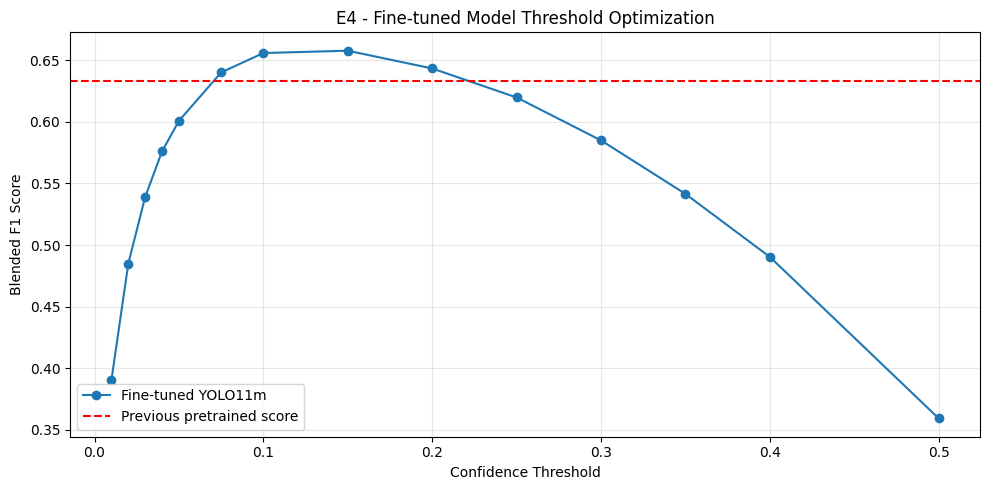

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    e4_df["Confidence"],
    e4_df["Final Score"],
    marker="o",
    label="Fine-tuned YOLO11m"
)

plt.axhline(
    y=0.633276,
    color="red",
    linestyle="--",
    label="Previous pretrained score"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Blended F1 Score")

plt.title("E4 - Fine-tuned Model Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/E4_threshold_optimization.png",
    dpi=200
)

plt.show()

In [34]:
best_e4 = e4_df.loc[
    e4_df["Final Score"].idxmax()
]

best_conf_e4 = float(best_e4["Confidence"])

best_score_e4 = float(best_e4["Final Score"])

print("Best confidence:", best_conf_e4)
print("Best local score:", best_score_e4)

print("Previous local score:", 0.633276)

print("Absolute improvement:",
      best_score_e4 - 0.633276)

display(best_e4)

Best confidence: 0.15
Best local score: 0.6577835633279705
Previous local score: 0.633276
Absolute improvement: 0.02450756332797055


Confidence          0.150000
Hard F1             0.649433
Soft F1             0.666135
Final Score         0.657784
Precision           0.722363
Recall              0.589878
Predictions     11407.000000
Ground Truth    13969.000000
Name: 7, dtype: float64

In [35]:
competition_dir = Path(
    "/kaggle/input/competitions/human-detection-ae"
)

sample = pd.read_csv(
    competition_dir / "sample_submission.csv"
)

image_map = {
    p.stem: str(p)
    for p in competition_dir.rglob("*.jpg")
}

image_paths = [
    image_map[image_id]
    for image_id in sample["image_id"]
]

print("Competition images:", len(image_paths))

assert len(image_paths) == 590

Competition images: 590


In [36]:
e4_test_predictions = run_inference(
    finetuned_model,
    image_paths,
    imgsz=1280,
    conf=best_conf_e4,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/295 [00:00<?, ?it/s]

Processed images: 590
Time: 110.02 seconds


In [37]:
def format_predictions(detections):

    parts = []

    for score, box in detections:

        x, y, w, h = box

        parts.append(
            f"1 {x:.6f} {y:.6f} {w:.6f} {h:.6f}"
        )

    return " ".join(parts) if parts else " "


submission_e4 = sample[["image_id"]].copy()

submission_e4["PredictionString"] = [
    format_predictions(e4_test_predictions[image_id])
    for image_id in submission_e4["image_id"]
]

submission_e4.to_csv(
    "/kaggle/working/E4_finetuned.csv",
    index=False
)

print(submission_e4.shape)
display(submission_e4.head())

(590, 2)


,image_id,PredictionString
0,test_00001,
1,test_00002,1 0.844309 0.210697 0.008229 0.024933
2,test_00003,1 0.480525 0.496699 0.025944 0.042240 1 0.4164...
3,test_00004,1 0.518383 0.490650 0.017114 0.023591 1 0.5524...
4,test_00005,1 0.511471 0.511030 0.011403 0.031941 1 0.4705...


In [38]:
check = pd.read_csv(
    "/kaggle/working/E4_finetuned.csv"
)

print("Shape:", check.shape)

print("Null values:",
      check.isna().sum().sum())

print("Correct ID ordering:",
      check["image_id"].equals(sample["image_id"]))

print("Invalid strings:",
      sum(
          len(str(s).split()) % 5 != 0
          for s in check["PredictionString"]
      ))

Shape: (590, 2)
Null values: 0
Correct ID ordering: True
Invalid strings: 0


In [39]:
from IPython.display import FileLink, display

display(FileLink("E4_finetuned.csv"))

/kaggle/working/E4_finetuned.csv

In [40]:
def inverse_rotate_box(box, k):

    x, y, w, h = box

    if k == 0:
        return [x, y, w, h]

    elif k == 1:
        return [1 - y, x, h, w]

    elif k == 2:
        return [1 - x, 1 - y, w, h]

    elif k == 3:
        return [y, 1 - x, h, w]

    else:
        raise ValueError("Invalid rotation")

In [41]:
import numpy as np

original_box = [0.3, 0.4, 0.1, 0.2]

rotated_boxes = [
    [0.3, 0.4, 0.1, 0.2],
    [0.4, 0.7, 0.2, 0.1],
    [0.7, 0.6, 0.1, 0.2],
    [0.6, 0.3, 0.2, 0.1]
]

for k, box in enumerate(rotated_boxes):

    recovered = inverse_rotate_box(box, k)

    assert np.allclose(
        recovered, original_box
    )

    print(f"Rotation {k * 90}: Passed")

Rotation 0: Passed
Rotation 90: Passed
Rotation 180: Passed
Rotation 270: Passed


In [42]:
def global_nms(detections, iou_threshold=0.45):

    detections = sorted(
        detections,
        key=lambda item: item[0],
        reverse=True
    )

    kept = []

    while detections:

        best = detections.pop(0)

        kept.append(best)

        detections = [
            det for det in detections

            if calculate_iou(
                best[1], det[1]
            ) <= iou_threshold
        ]

    return kept

In [43]:
import cv2
import time
from tqdm.auto import tqdm

def run_rotation_tta(
    model,
    paths,
    imgsz=1280,
    conf=0.03,
    iou=0.45
):

    predictions = {}

    start = time.time()

    for path in tqdm(paths):

        image = cv2.imread(str(path))

        if image is None:
            raise ValueError(f"Cannot read {path}")

        image_id = Path(path).stem

        all_detections = []

        for k in range(4):

            rotated_image = np.ascontiguousarray(
                np.rot90(image, k)
            )

            result = model.predict(
                source=rotated_image,
                imgsz=imgsz,
                conf=conf,
                iou=0.45,
                classes=[0],
                device=0,
                max_det=300,
                verbose=False
            )[0]

            boxes = result.boxes.xywhn.cpu().tolist()

            scores = result.boxes.conf.cpu().tolist()

            for score, box in zip(scores, boxes):

                restored_box = inverse_rotate_box(
                    box, k
                )

                all_detections.append(
                    (score, restored_box)
                )

        predictions[image_id] = global_nms(
            all_detections,
            iou_threshold=iou
        )

    print("Processed images:", len(predictions))

    print(
        "Time:",
        round(time.time() - start, 2),
        "seconds"
    )

    return predictions

In [44]:
tta_val_predictions = run_rotation_tta(
    finetuned_model,
    val_image_paths,
    imgsz=1280,
    conf=0.03,
    iou=0.45
)

  0%|          | 0/548 [00:00<?, ?it/s]

Processed images: 548
Time: 204.21 seconds


In [45]:
import json

with open(
    "/kaggle/working/E5_tta_val_predictions.json",
    "w"
) as f:

    json.dump(tta_val_predictions, f)

In [46]:
tta_thresholds = [
    0.03, 0.05, 0.075,
    0.10, 0.125, 0.15,
    0.175, 0.20, 0.25,
    0.30, 0.35, 0.40
]

tta_results = []

for conf in tqdm(tta_thresholds):

    metrics = evaluate_predictions(
        tta_val_predictions,
        ground_truth,
        conf_threshold=conf
    )

    tta_results.append({
        "Confidence": conf,
        **metrics
    })

tta_df = pd.DataFrame(tta_results)

display(tta_df)

  0%|          | 0/12 [00:00<?, ?it/s]

,Confidence,Hard F1,Soft F1,Final Score,Precision,Recall,Predictions,Ground Truth
0,0.030,0.336926,0.347180,0.342053,0.208500,0.877300,58777,13969
1,0.050,0.417795,0.430857,0.424326,0.277490,0.845086,42542,13969
2,0.075,0.488273,0.503704,0.495989,0.349881,0.807789,32251,13969
3,0.100,0.538878,0.555334,0.547106,0.413403,0.773713,26144,13969
4,0.125,0.579032,0.596020,0.587526,0.473739,0.744506,21953,13969
5,0.150,0.605251,0.622787,0.614019,0.526296,0.712077,18900,13969
6,0.175,0.623370,0.640645,0.632007,0.574778,0.680936,16549,13969
7,0.200,0.635365,0.652957,0.644161,0.621365,0.650011,14613,13969
8,0.250,0.642701,0.657832,0.650267,0.704792,0.590665,11707,13969
9,0.300,0.627549,0.640424,0.633987,0.774380,0.527525,9516,13969


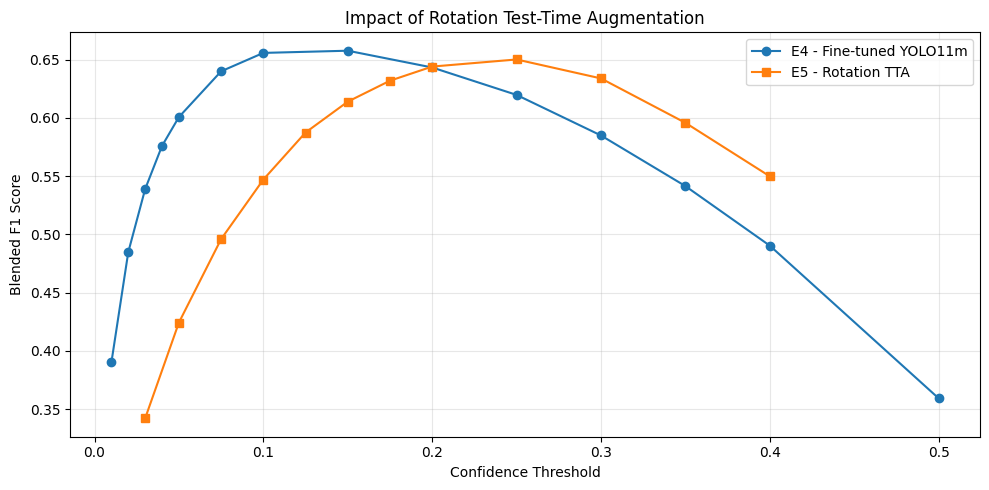

In [47]:
plt.figure(figsize=(10, 5))

plt.plot(
    e4_df["Confidence"],
    e4_df["Final Score"],
    marker="o",
    label="E4 - Fine-tuned YOLO11m"
)

plt.plot(
    tta_df["Confidence"],
    tta_df["Final Score"],
    marker="s",
    label="E5 - Rotation TTA"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Blended F1 Score")

plt.title("Impact of Rotation Test-Time Augmentation")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/E5_rotation_tta.png",
    dpi=200
)

plt.show()

In [48]:
best_e5 = tta_df.loc[
    tta_df["Final Score"].idxmax()
]

best_conf_e5 = float(
    best_e5["Confidence"]
)

best_score_e5 = float(
    best_e5["Final Score"]
)

print("Best TTA confidence:", best_conf_e5)

print("Best TTA score:", best_score_e5)

print("Previous E4 score:", best_score_e4)

print(
    "Absolute improvement:",
    best_score_e5 - best_score_e4
)

display(best_e5)

Best TTA confidence: 0.25
Best TTA score: 0.6502669126807672
Previous E4 score: 0.6577835633279705
Absolute improvement: -0.0075166506472033046


Confidence          0.250000
Hard F1             0.642701
Soft F1             0.657832
Final Score         0.650267
Precision           0.704792
Recall              0.590665
Predictions     11707.000000
Ground Truth    13969.000000
Name: 8, dtype: float64

In [49]:
e5_test_predictions = run_rotation_tta(
    finetuned_model,
    image_paths,
    imgsz=1280,
    conf=0.03,
    iou=0.45
)

  0%|          | 0/590 [00:00<?, ?it/s]

Processed images: 590
Time: 202.05 seconds


In [50]:
submission_e5 = sample[["image_id"]].copy()

submission_e5["PredictionString"] = [
    format_predictions([
        (score, box)
        for score, box in e5_test_predictions[image_id]
        if score >= best_conf_e5
    ])
    for image_id in submission_e5["image_id"]
]

submission_e5.to_csv(
    "/kaggle/working/E5_rotation_tta.csv",
    index=False
)

In [51]:
check = pd.read_csv(
    "/kaggle/working/E5_rotation_tta.csv"
)

print("Shape:", check.shape)
print("Null values:", check.isna().sum().sum())

print("Correct ID ordering:",
      check["image_id"].equals(sample["image_id"]))

print("Invalid strings:", sum(
    len(str(s).split()) % 5 != 0
    for s in check["PredictionString"]
))

Shape: (590, 2)
Null values: 0
Correct ID ordering: True
Invalid strings: 0


In [52]:
display(FileLink("E5_rotation_tta.csv"))

/kaggle/working/E5_rotation_tta.csv

In [53]:
def restore_tile_box(box, x0, y0, tw, th, W, H):

    x, y, w, h = box

    return [
        (x0 + x * tw) / W,
        (y0 + y * th) / H,
        w * tw / W,
        h * th / H
    ]

In [54]:
box = [0.5, 0.5, 0.2, 0.4]

restored = restore_tile_box(
    box,
    x0=400,
    y0=200,
    tw=400,
    th=400,
    W=1000,
    H=800
)

expected = [0.6, 0.5, 0.08, 0.2]

assert np.allclose(restored, expected)

print("Tile coordinate mapping: Passed")

Tile coordinate mapping: Passed


In [55]:
def generate_tiles(image):

    H, W = image.shape[:2]

    tw = int(W * 0.6)
    th = int(H * 0.6)

    x_positions = [0, W - tw]
    y_positions = [0, H - th]

    tiles = []

    for y in y_positions:

        for x in x_positions:

            tile = image[y:y + th, x:x + tw]

            tiles.append((tile, x, y))

    return tiles

In [56]:
def run_tiled_inference(
    model,
    paths,
    full_predictions,
    imgsz=960,
    conf=0.03,
    iou=0.45
):

    predictions = {}

    start = time.time()

    for path in tqdm(paths):

        image = cv2.imread(str(path))

        if image is None:
            raise ValueError(f"Cannot read {path}")

        H, W = image.shape[:2]

        image_id = Path(path).stem

        all_detections = list(
            full_predictions[image_id]
        )

        for tile, x0, y0 in generate_tiles(image):

            th, tw = tile.shape[:2]

            result = model.predict(
                source=tile,
                imgsz=imgsz,
                conf=conf,
                iou=0.45,
                classes=[0],
                device=0,
                max_det=300,
                verbose=False
            )[0]

            boxes = result.boxes.xywhn.cpu().tolist()
            scores = result.boxes.conf.cpu().tolist()

            for score, box in zip(scores, boxes):

                restored = restore_tile_box(
                    box, x0, y0, tw, th, W, H
                )

                all_detections.append(
                    (score, restored)
                )

        predictions[image_id] = global_nms(
            all_detections,
            iou_threshold=iou
        )

    print("Processed images:", len(predictions))
    print("Time:", round(time.time() - start, 2))

    return predictions

In [57]:
tiled_val_predictions = run_tiled_inference(
    finetuned_model,
    val_image_paths,
    finetuned_val_predictions,
    imgsz=960,
    conf=0.03,
    iou=0.45
)

  0%|          | 0/548 [00:00<?, ?it/s]

Processed images: 548
Time: 115.03


In [58]:
with open(
    "/kaggle/working/E6_tiled_val_predictions.json",
    "w"
) as f:

    json.dump(tiled_val_predictions, f)

In [59]:
tile_thresholds = [
    0.03, 0.05, 0.075,
    0.10, 0.125, 0.15,
    0.175, 0.20, 0.225,
    0.25, 0.30, 0.35, 0.40
]

tile_results = []

for conf in tqdm(tile_thresholds):

    metrics = evaluate_predictions(
        tiled_val_predictions,
        ground_truth,
        conf_threshold=conf
    )

    tile_results.append({
        "Confidence": conf,
        **metrics
    })

tile_df = pd.DataFrame(tile_results)

display(tile_df)

  0%|          | 0/13 [00:00<?, ?it/s]

,Confidence,Hard F1,Soft F1,Final Score,Precision,Recall,Predictions,Ground Truth
0,0.030,0.462598,0.480606,0.471602,0.322227,0.819672,35534,13969
1,0.050,0.538722,0.559226,0.548974,0.411705,0.779082,26434,13969
2,0.075,0.591710,0.613853,0.602782,0.493219,0.739351,20940,13969
3,0.100,0.621766,0.643074,0.632420,0.555405,0.706135,17760,13969
4,0.125,0.639846,0.661705,0.650775,0.607134,0.676283,15560,13969
5,0.150,0.647883,0.669037,0.658460,0.648837,0.646932,13928,13969
6,0.175,0.650902,0.672050,0.661476,0.686606,0.618727,12588,13969
7,0.200,0.650116,0.669816,0.659966,0.720317,0.592383,11488,13969
8,0.225,0.645845,0.663629,0.654737,0.750213,0.566970,10557,13969
9,0.250,0.639033,0.654692,0.646862,0.776356,0.542988,9770,13969


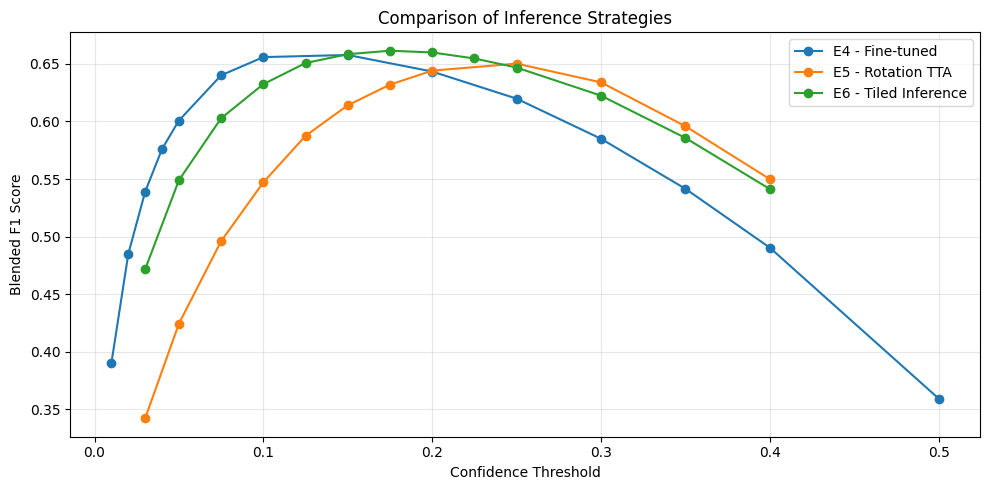

In [60]:
plt.figure(figsize=(10, 5))

for df, name in [
    (e4_df, "E4 - Fine-tuned"),
    (tta_df, "E5 - Rotation TTA"),
    (tile_df, "E6 - Tiled Inference")
]:

    plt.plot(
        df["Confidence"],
        df["Final Score"],
        marker="o",
        label=name
    )

plt.xlabel("Confidence Threshold")
plt.ylabel("Blended F1 Score")

plt.title("Comparison of Inference Strategies")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/E6_inference_comparison.png",
    dpi=200
)

plt.show()

In [61]:
best_e6 = tile_df.loc[
    tile_df["Final Score"].idxmax()
]

best_conf_e6 = float(best_e6["Confidence"])
best_score_e6 = float(best_e6["Final Score"])

print("Best Tiling confidence:", best_conf_e6)
print("Best Tiling score:", best_score_e6)
print("Previous E4 score:", best_score_e4)

print(
    "Absolute improvement:",
    best_score_e6 - best_score_e4
)

display(best_e6)

Best Tiling confidence: 0.175
Best Tiling score: 0.6614760891574136
Previous E4 score: 0.6577835633279705
Absolute improvement: 0.0036925258294431273


Confidence          0.175000
Hard F1             0.650902
Soft F1             0.672050
Final Score         0.661476
Precision           0.686606
Recall              0.618727
Predictions     12588.000000
Ground Truth    13969.000000
Name: 6, dtype: float64

In [62]:
e6_full_test_predictions = run_inference(
    finetuned_model,
    image_paths,
    imgsz=1280,
    conf=0.01,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/295 [00:00<?, ?it/s]

Processed images: 590
Time: 95.79 seconds


In [63]:
e6_test_predictions = run_tiled_inference(
    finetuned_model,
    image_paths,
    e6_full_test_predictions,
    imgsz=960,
    conf=0.03,
    iou=0.45
)

  0%|          | 0/590 [00:00<?, ?it/s]

Processed images: 590
Time: 111.2


In [64]:
with open(
    "/kaggle/working/E6_test_predictions.json", "w"
) as f:
    json.dump(e6_test_predictions, f)

In [65]:
submission_e6 = sample[["image_id"]].copy()

submission_e6["PredictionString"] = [
    format_predictions([
        (score, box)
        for score, box in e6_test_predictions[image_id]
        if score >= best_conf_e6
    ])
    for image_id in submission_e6["image_id"]
]

submission_e6.to_csv(
    "/kaggle/working/E6_tiled.csv",
    index=False
)

In [66]:
check = pd.read_csv(
    "/kaggle/working/E6_tiled.csv"
)

print("Shape:", check.shape)
print("Null values:", check.isna().sum().sum())

print("Correct ID ordering:",
      check["image_id"].equals(sample["image_id"]))

print("Invalid strings:", sum(
    len(str(s).split()) % 5 != 0
    for s in check["PredictionString"]
))

Shape: (590, 2)
Null values: 0
Correct ID ordering: True
Invalid strings: 0


In [67]:
display(FileLink("E6_tiled.csv"))

/kaggle/working/E6_tiled.csv

In [68]:
!pip install -q ensemble-boxes

In [69]:
from ultralytics import YOLO

pretrained_model = YOLO("yolo11m.pt")

print("Pretrained:", pretrained_model.names[0])
print("Fine-tuned:", finetuned_model.names[0])

Pretrained: person
Fine-tuned: human


In [70]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

pretrained_val_predictions = run_inference(
    pretrained_model,
    val_image_paths,
    imgsz=1280,
    conf=0.01,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/274 [00:00<?, ?it/s]

Processed images: 548
Time: 55.07 seconds


In [71]:
import json

with open(
    "/kaggle/working/E7_pretrained_val.json", "w"
) as f:
    json.dump(pretrained_val_predictions, f)

metrics = evaluate_predictions(
    pretrained_val_predictions,
    ground_truth,
    conf_threshold=0.04
)

display(pd.Series(metrics))

Hard F1             0.629729
Soft F1             0.637966
Final Score         0.633847
Precision           0.690920
Recall              0.578495
Predictions     11696.000000
Ground Truth    13969.000000
dtype: float64

In [72]:
def xyxy_to_xywh(box):

    x1, y1, x2, y2 = box

    return [
        (x1 + x2) / 2,
        (y1 + y2) / 2,
        x2 - x1,
        y2 - y1
    ]

In [73]:
from ensemble_boxes import weighted_boxes_fusion
import numpy as np


def ensemble_predictions(
    pretrained_predictions,
    finetuned_predictions,
    weights=(1, 2),
    conf_pretrained=0.04,
    conf_finetuned=0.15,
    fusion_iou=0.45
):

    predictions = {}

    assert (
        pretrained_predictions.keys()
        == finetuned_predictions.keys()
    )

    for image_id in pretrained_predictions:

        model_detections = [

            [
                (score, box)
                for score, box in
                pretrained_predictions[image_id]
                if score >= conf_pretrained
            ],

            [
                (score, box)
                for score, box in
                finetuned_predictions[image_id]
                if score >= conf_finetuned
            ]
        ]

        boxes_list = []
        scores_list = []
        labels_list = []

        for detections in model_detections:

            boxes = [
                np.clip(
                    xywh_to_xyxy(box), 0, 1
                ).tolist()
                for score, box in detections
            ]

            scores = [
                score for score, box in detections
            ]

            labels = [0] * len(boxes)

            boxes_list.append(boxes)
            scores_list.append(scores)
            labels_list.append(labels)

        boxes, scores, labels = weighted_boxes_fusion(
            boxes_list,
            scores_list,
            labels_list,
            weights=list(weights),
            iou_thr=fusion_iou,
            skip_box_thr=0.0,
            conf_type="avg"
        )

        predictions[image_id] = [
            (float(score), xyxy_to_xywh(box))
            for score, box in zip(scores, boxes)
        ]

    return predictions

In [74]:
from itertools import product

weight_options = [
    (1, 1),
    (1, 2),
    (1, 3)
]

iou_options = [
    0.35,
    0.45,
    0.55
]

output_thresholds = [
    0.0,
    0.05,
    0.10,
    0.15
]

ensemble_results = []

for weights, fusion_iou in tqdm(
    list(product(weight_options, iou_options))
):

    fused = ensemble_predictions(
        pretrained_val_predictions,
        finetuned_val_predictions,
        weights=weights,
        conf_pretrained=0.04,
        conf_finetuned=0.15,
        fusion_iou=fusion_iou
    )

    for conf in output_thresholds:

        metrics = evaluate_predictions(
            fused,
            ground_truth,
            conf_threshold=conf
        )

        ensemble_results.append({

            "Pretrained Weight": weights[0],
            "Fine-tuned Weight": weights[1],
            "Fusion IoU": fusion_iou,
            "Output Confidence": conf,

            **metrics
        })

ensemble_df = pd.DataFrame(ensemble_results)

display(
    ensemble_df.sort_values(
        "Final Score",
        ascending=False
    ).head(10)
)

  0%|          | 0/9 [00:00<?, ?it/s]

,Pretrained Weight,Fine-tuned Weight,Fusion IoU,Output Confidence,Hard F1,Soft F1,Final Score,Precision,Recall,Predictions,Ground Truth
1,1,1,0.35,0.05,0.673029,0.684611,0.678820,0.708175,0.641206,12648,13969
2,1,1,0.35,0.10,0.670361,0.680908,0.675635,0.778019,0.588875,10573,13969
13,1,2,0.35,0.05,0.668515,0.681235,0.674875,0.723491,0.621304,11996,13969
25,1,3,0.35,0.05,0.665444,0.678505,0.671975,0.731469,0.610351,11656,13969
14,1,2,0.35,0.10,0.663055,0.676251,0.669653,0.740744,0.600115,11317,13969
6,1,1,0.45,0.10,0.663530,0.674907,0.669219,0.748830,0.595676,11112,13969
17,1,2,0.45,0.05,0.661799,0.675831,0.668815,0.689971,0.635836,12873,13969
5,1,1,0.45,0.05,0.662092,0.674805,0.668449,0.671725,0.652731,13574,13969
29,1,3,0.45,0.05,0.659816,0.674435,0.667126,0.698528,0.625170,12502,13969
18,1,2,0.45,0.10,0.658161,0.672983,0.665572,0.710504,0.613000,12052,13969


In [75]:
best_e7 = ensemble_df.loc[
    ensemble_df["Final Score"].idxmax()
]

best_score_e7 = float(
    best_e7["Final Score"]
)

print("Best Ensemble Score:", best_score_e7)

print("Previous E4 Score:", best_score_e4)

print(
    "Absolute Improvement:",
    best_score_e7 - best_score_e4
)

display(best_e7)

Best Ensemble Score: 0.6788195644669469
Previous E4 Score: 0.6577835633279705
Absolute Improvement: 0.021036001138976412


Pretrained Weight        1.000000
Fine-tuned Weight        1.000000
Fusion IoU               0.350000
Output Confidence        0.050000
Hard F1                  0.673029
Soft F1                  0.684611
Final Score              0.678820
Precision                0.708175
Recall                   0.641206
Predictions          12648.000000
Ground Truth         13969.000000
Name: 1, dtype: float64

In [77]:
ensemble_df.to_csv(
    "/kaggle/working/E7_ensemble_search.csv",
    index=False
)

In [78]:
pretrained_test_predictions = run_inference(
    pretrained_model,
    image_paths,
    imgsz=1280,
    conf=0.01,
    iou=0.45,
    batch_size=2
)

  0%|          | 0/295 [00:00<?, ?it/s]

Processed images: 590
Time: 96.63 seconds


In [79]:
e7_test_predictions = ensemble_predictions(

    pretrained_test_predictions,

    e6_full_test_predictions,

    weights=(
        int(best_e7["Pretrained Weight"]),
        int(best_e7["Fine-tuned Weight"])
    ),

    conf_pretrained=0.04,
    conf_finetuned=0.15,

    fusion_iou=float(best_e7["Fusion IoU"])
)

best_conf_e7 = float(
    best_e7["Output Confidence"]
)

print("Processed images:", len(e7_test_predictions))
print("Output confidence:", best_conf_e7)

Processed images: 590
Output confidence: 0.05


In [80]:
with open(
    "/kaggle/working/E7_test_predictions.json", "w"
) as f:

    json.dump(e7_test_predictions, f)

In [82]:
submission_e7 = sample[["image_id"]].copy()

submission_e7["PredictionString"] = [
    format_predictions([
        (score, box)
        for score, box in e7_test_predictions[image_id]
        if score >= best_conf_e7
    ])
    for image_id in submission_e7["image_id"]
]

submission_e7.to_csv(
    "/kaggle/working/E7_ensemble.csv",
    index=False
)

In [83]:
check = pd.read_csv(
    "/kaggle/working/E7_ensemble.csv"
)

print("Shape:", check.shape)

print("Null values:",
      check.isna().sum().sum())

print("Correct ID ordering:",
      check["image_id"].equals(sample["image_id"]))

print("Invalid strings:", sum(
    len(str(s).split()) % 5 != 0
    for s in check["PredictionString"]
))

Shape: (590, 2)
Null values: 0
Correct ID ordering: True
Invalid strings: 0


In [84]:
display(FileLink("E7_ensemble.csv"))

/kaggle/working/E7_ensemble.csv

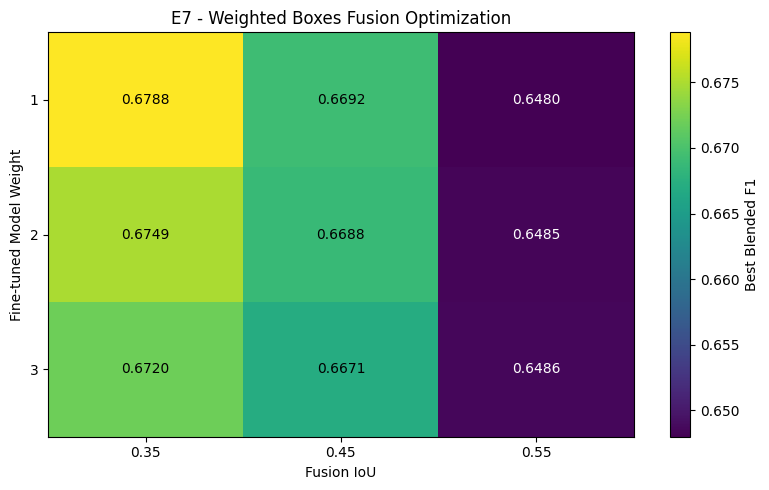

In [85]:
pivot = ensemble_df.pivot_table(
    index="Fine-tuned Weight",
    columns="Fusion IoU",
    values="Final Score",
    aggfunc="max"
)

plt.figure(figsize=(8, 5))

plt.imshow(
    pivot.values,
    cmap="viridis",
    aspect="auto"
)

plt.colorbar(label="Best Blended F1")

plt.xticks(
    range(len(pivot.columns)),
    pivot.columns
)

plt.yticks(
    range(len(pivot.index)),
    pivot.index
)

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):

        plt.text(
            j, i,
            f"{pivot.iloc[i, j]:.4f}",
            ha="center",
            va="center",
            color="white" if pivot.iloc[i, j] <
            pivot.values.mean() else "black"
        )

plt.xlabel("Fusion IoU")
plt.ylabel("Fine-tuned Model Weight")
plt.title("E7 - Weighted Boxes Fusion Optimization")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/E7_ensemble_heatmap.png",
    dpi=200
)

plt.show()

In [86]:
extended_ious = [
    0.15, 0.20, 0.25,
    0.30, 0.35
]

extended_confidences = [
    0.025, 0.05, 0.075, 0.10
]

e8_results = []

for fusion_iou in tqdm(extended_ious):

    fused = ensemble_predictions(
        pretrained_val_predictions,
        finetuned_val_predictions,
        weights=(1, 1),
        conf_pretrained=0.04,
        conf_finetuned=0.15,
        fusion_iou=fusion_iou
    )

    for conf in extended_confidences:

        metrics = evaluate_predictions(
            fused,
            ground_truth,
            conf_threshold=conf
        )

        e8_results.append({
            "Fusion IoU": fusion_iou,
            "Output Confidence": conf,
            **metrics
        })

e8_df = pd.DataFrame(e8_results)

display(
    e8_df.sort_values(
        "Final Score",
        ascending=False
    ).head(10)
)

  0%|          | 0/5 [00:00<?, ?it/s]

,Fusion IoU,Output Confidence,Hard F1,Soft F1,Final Score,Precision,Recall,Predictions,Ground Truth
17,0.35,0.050,0.673029,0.684611,0.678820,0.708175,0.641206,12648,13969
13,0.30,0.050,0.672756,0.683609,0.678183,0.718245,0.632687,12305,13969
18,0.35,0.075,0.671820,0.683449,0.677634,0.725800,0.625313,12035,13969
14,0.30,0.075,0.671439,0.682343,0.676891,0.735384,0.617725,11734,13969
19,0.35,0.100,0.670361,0.680908,0.675635,0.778019,0.588875,10573,13969
9,0.25,0.050,0.670103,0.680647,0.675375,0.724204,0.623524,12027,13969
15,0.30,0.100,0.669598,0.679317,0.674457,0.786011,0.583220,10365,13969
10,0.25,0.075,0.668186,0.678930,0.673558,0.740550,0.608705,11482,13969
11,0.25,0.100,0.665673,0.675296,0.670485,0.789241,0.575560,10187,13969
12,0.30,0.025,0.663763,0.675826,0.669795,0.673270,0.654521,13580,13969


In [87]:
best_e8 = e8_df.loc[
    e8_df["Final Score"].idxmax()
]

best_score_e8 = float(
    best_e8["Final Score"]
)

print("Best E8 score:", best_score_e8)

print("Previous E7 score:", best_score_e7)

print(
    "Absolute improvement:",
    best_score_e8 - best_score_e7
)

display(best_e8)

Best E8 score: 0.6788195644669469
Previous E7 score: 0.6788195644669469
Absolute improvement: 0.0


Fusion IoU               0.350000
Output Confidence        0.050000
Hard F1                  0.673029
Soft F1                  0.684611
Final Score              0.678820
Precision                0.708175
Recall                   0.641206
Predictions          12648.000000
Ground Truth         13969.000000
Name: 17, dtype: float64

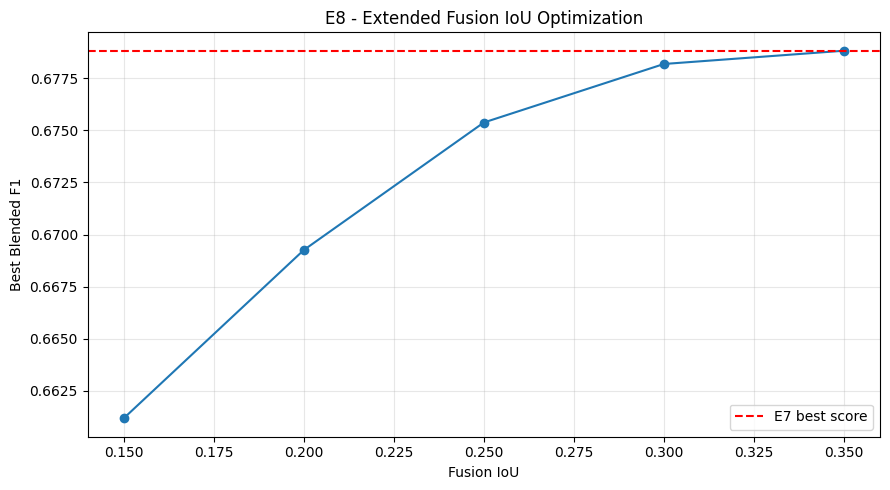

In [88]:
fusion_summary = e8_df.groupby(
    "Fusion IoU"
)["Final Score"].max()

plt.figure(figsize=(9, 5))

plt.plot(
    fusion_summary.index,
    fusion_summary.values,
    marker="o"
)

plt.axhline(
    best_score_e7,
    color="red",
    linestyle="--",
    label="E7 best score"
)

plt.xlabel("Fusion IoU")
plt.ylabel("Best Blended F1")
plt.title("E8 - Extended Fusion IoU Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/E8_fusion_optimization.png",
    dpi=200
)

plt.show()

In [89]:
final_results = pd.DataFrame([
    ["E1", "Pretrained Baseline", 0.266290, 0.55109],
    ["E2", "High-Resolution Inference", 0.499251, None],
    ["E3", "Confidence Optimization", 0.633276, 0.70867],
    ["E4", "Aerial Fine-tuning", best_score_e4, 0.75743],
    ["E5", "Rotation TTA", best_score_e5, 0.73712],
    ["E6", "Tiled Inference", best_score_e6, 0.67211],
    ["E7", "Weighted Boxes Fusion", best_score_e7, 0.79575],
    ["E8", "Extended Fusion Search", best_score_e8, None]
], columns=[
    "Experiment",
    "Method",
    "Local F1",
    "Kaggle Public Score"
])

display(final_results)

final_results.to_csv(
    "/kaggle/working/final_results.csv",
    index=False
)

,Experiment,Method,Local F1,Kaggle Public Score
0,E1,Pretrained Baseline,0.266290,0.55109
1,E2,High-Resolution Inference,0.499251,NaN
2,E3,Confidence Optimization,0.633276,0.70867
3,E4,Aerial Fine-tuning,0.657784,0.75743
4,E5,Rotation TTA,0.650267,0.73712
5,E6,Tiled Inference,0.661476,0.67211
6,E7,Weighted Boxes Fusion,0.678820,0.79575
7,E8,Extended Fusion Search,0.678820,NaN


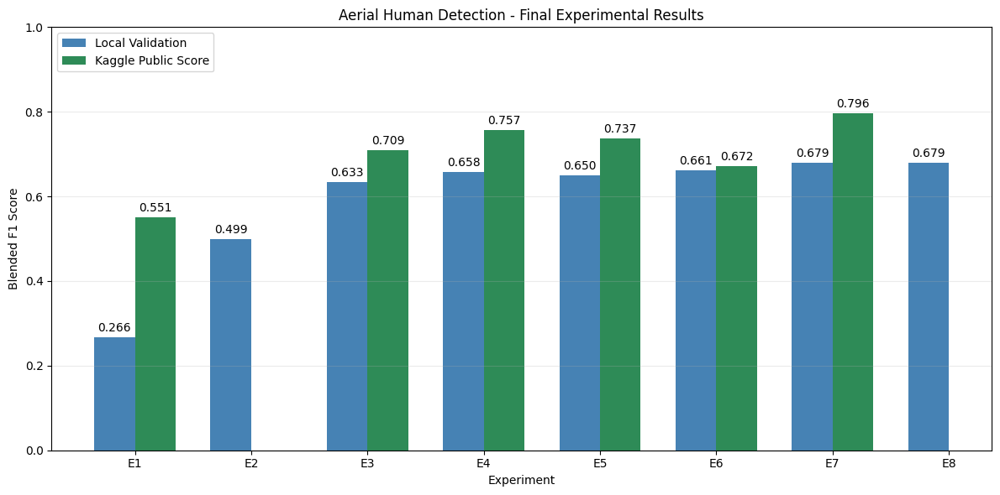

In [90]:
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(final_results))
width = 0.35

ax.bar(
    x - width/2,
    final_results["Local F1"],
    width,
    label="Local Validation",
    color="steelblue"
)

ax.bar(
    x + width/2,
    final_results["Kaggle Public Score"],
    width,
    label="Kaggle Public Score",
    color="seagreen"
)

ax.set_xticks(x)
ax.set_xticklabels(final_results["Experiment"])

ax.set_ylabel("Blended F1 Score")
ax.set_xlabel("Experiment")
ax.set_title("Aerial Human Detection - Final Experimental Results")

ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.3f}"
        if np.isfinite(bar.get_height()) else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/final_performance.png",
    dpi=300
)

plt.show()

In [91]:
final_config = {
    "experiment": "E7",
    "method": "Weighted Boxes Fusion",
    "pretrained_model": "yolo11m.pt",
    "finetuned_model": "E4_aerial_best.pt",
    "image_size": 1280,
    "pretrained_confidence": 0.04,
    "finetuned_confidence": 0.15,
    "nms_iou": 0.45,
    "max_det": 300,
    "model_weights": [1, 1],
    "fusion_iou": 0.35,
    "output_confidence": 0.05,
    "local_score": best_score_e7,
    "kaggle_public_score": 0.79575
}

with open(
    "/kaggle/working/final_config.json", "w"
) as f:
    json.dump(final_config, f, indent=4)

print("Final configuration saved.")

Final configuration saved.


In [92]:
import zipfile
from pathlib import Path

root = Path("/kaggle/working")

patterns = [
    "*.png",
    "*.csv",
    "*.json",
    "*.yaml",
    "E4_aerial_best.pt",
    "yolo11m.pt"
]

selected_files = set()

for pattern in patterns:
    selected_files.update(root.glob(pattern))

training_files = [
    root / "experiments/E4_aerial_training/results.csv",
    root / "experiments/E4_aerial_training/args.yaml",
    root / "experiments/E4_aerial_training/weights/best.pt"
]

for path in training_files:
    if path.is_file():
        selected_files.add(path)

zip_path = root / "Aerial_Human_Detection_Backup.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:

    for path in sorted(selected_files):

        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(root)
            )

            print("Saved:", path.name)

print("\nBackup created successfully.")

Saved: E4_aerial_best.pt
Saved: E4_finetuned.csv
Saved: E4_threshold_optimization.png
Saved: E4_training_loss.png
Saved: E4_val_predictions.json
Saved: E4_validation_metrics.png
Saved: E5_rotation_tta.csv
Saved: E5_rotation_tta.png
Saved: E5_tta_val_predictions.json
Saved: E6_inference_comparison.png
Saved: E6_test_predictions.json
Saved: E6_tiled.csv
Saved: E6_tiled_val_predictions.json
Saved: E7_ensemble.csv
Saved: E7_ensemble_heatmap.png
Saved: E7_ensemble_search.csv
Saved: E7_pretrained_val.json
Saved: E7_test_predictions.json
Saved: E8_fusion_optimization.png
Saved: args.yaml
Saved: results.csv
Saved: best.pt
Saved: final_config.json
Saved: final_performance.png
Saved: final_results.csv
Saved: human_data.yaml
Saved: yolo11m.pt

Backup created successfully.


In [93]:
from IPython.display import FileLink, display

display(
    FileLink("Aerial_Human_Detection_Backup.zip")
)

/kaggle/working/Aerial_Human_Detection_Backup.zip

In [94]:
from pathlib import Path

root = Path("/kaggle/working")

for name in [
    "E4_aerial_best.pt",
    "yolo11m.pt",
    "final_config.json"
]:
    print(name, ":", (root / name).exists())

E4_aerial_best.pt : True
yolo11m.pt : True
final_config.json : True


In [95]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("inference.py"):
    print(p)

/kaggle/input/datasets/malakaldamer/inference/inference.py


In [96]:
import shutil

root = Path("/kaggle/working")

script = next(
    Path("/kaggle/input").rglob("inference.py")
)

shutil.copy2(script, root / "inference.py")

weights_dir = root / "weights"
weights_dir.mkdir(exist_ok=True)

for name in ["yolo11m.pt", "E4_aerial_best.pt"]:
    shutil.copy2(root / name, weights_dir / name)

print("Project files are ready.")

Project files are ready.


In [97]:
%cd /kaggle/working

!python inference.py --help

/kaggle/working
usage: inference.py [-h] --images IMAGES [--sample SAMPLE] [--output OUTPUT]
                    [--device DEVICE]

E7: COCO and VisDrone YOLO11m ensemble for human detection.

options:
  -h, --help       show this help message and exit
  --images IMAGES
  --sample SAMPLE  Optional sample CSV for image order
  --output OUTPUT
  --device DEVICE  0 for GPU or cpu


In [98]:
demo_dir = root / "demo"
demo_dir.mkdir(exist_ok=True)

image = next(
    Path("/kaggle/working/visdrone/VisDrone2019-DET-val/images").glob("*.jpg")
)

shutil.copy2(image, demo_dir / image.name)

print("Demo image:", image.name)

Demo image: 0000242_02400_d_0000009.jpg


In [99]:
!python inference.py --images demo --output demo_result.csv --device 0

Processed 1/1
Saved demo_result.csv


In [100]:
import pandas as pd

demo_result = pd.read_csv(
    "/kaggle/working/demo_result.csv"
)

display(demo_result)

,image_id,PredictionString
0,0000242_02400_d_0000009,1 0.241391 0.103606 0.009637 0.031224 1 0.4891...


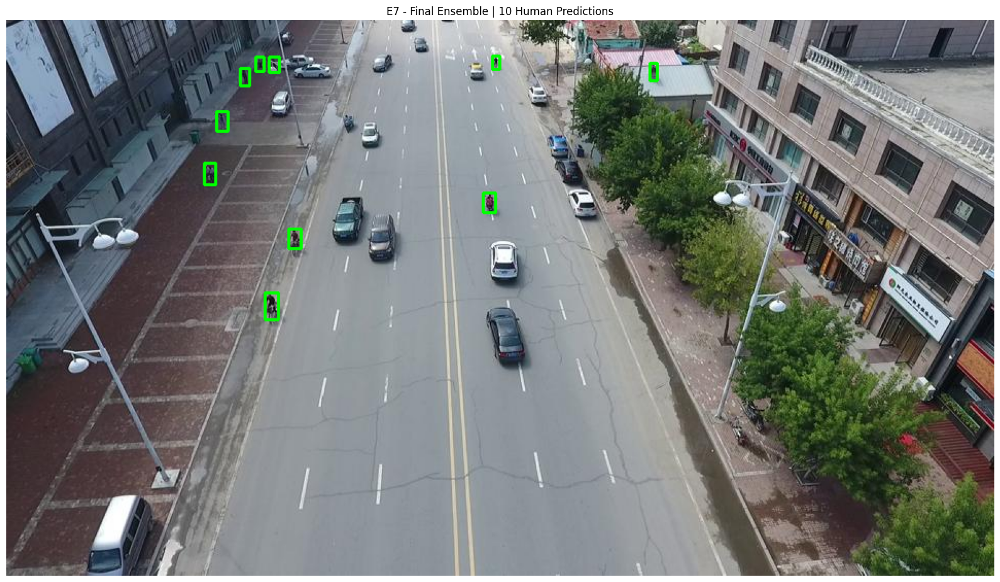

Total detections: 10


In [101]:
import cv2
import matplotlib.pyplot as plt

image_path = next(demo_dir.glob("*.jpg"))

image = cv2.imread(str(image_path))

H, W = image.shape[:2]

tokens = demo_result["PredictionString"].iloc[0].split()

assert len(tokens) % 5 == 0

count = 0

for i in range(0, len(tokens), 5):

    cls, x, y, w, h = map(float, tokens[i:i+5])

    x1 = int((x - w/2) * W)
    y1 = int((y - h/2) * H)

    x2 = int((x + w/2) * W)
    y2 = int((y + h/2) * H)

    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    count += 1

plt.figure(figsize=(16, 10))

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

plt.title(f"E7 - Final Ensemble | {count} Human Predictions")

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/E7_final_demo.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Total detections:", count)

In [102]:
display(FileLink("E7_final_demo.png"))

/kaggle/working/E7_final_demo.png